# Research Question

What factors/characteristics contribute to injury severity from the years 2022-2025?

# 📌 Handoff Notes: Changes Made Oct 23 (Evening)
*For Kelly and Victoria. Read this first. Nothing you wrote was deleted; changes are additions plus a few short "Update" notes.*

**To run:** Runtime → Restart session and run all. Every section depends on the cleaning section, so a partial rerun will mix old and new results. Needs `xgboost` (preinstalled in Colab) and `imbalanced-learn` (installed by the `%pip` cell).

## 1. Data fix: category labels changed in 2024 (cleaning section)
While debugging why SMOTENC predicted only "No Apparent Injury", we found that **Montgomery County renamed the categories for several fields starting in 2024**. For example, `PASSENGER CAR` became `Passenger Car`, `North` became `Northbound`, `County` became `County Route`, and `MAKING LEFT TURN` became `Turning Left`. Only 5 of 33 body-type labels matched between 2022-2023 and 2024-2025. So every model trained on 2022-2023 treated **Vehicle Body Type, Vehicle Movement, Vehicle Going Dir, and Route Type** as unknown values on 2024 data.

- **New section:** *Harmonize category labels that changed in 2024*, right after *Group collision types*. It maps old labels onto the 2024+ wording and prints any label that still appears in only one period. The judgment calls are listed in that section.
- **Kelly:** this changes the saved CSVs and some EDA charts, which now show one category where they used to show two (e.g. `PASSENGER CAR` and `Passenger Car`). Collision Group was **not** changed. It still has "Turning (same direction)" and "Opposing left turns" only before 2024 and "Rear to Rear" only after, because the Collision Type scheme changed too. Worth a look.
- **Victoria:** all modeling numbers changed after the fix. I added short "Update" notes under your *Notes: After EDA Imputation* and under the GPT interpretation, since that text describes the first run.

## 2. New modeling sections (end of notebook)
| Section | What it does |
|---|---|
| **Tree-Based Models (Four-Class Target)** | Random Forest, Histogram Gradient Boosting, and XGBoost on the same 2022-2023 train / 2024 validation split and four-class target as Experiment B |
| **Class Balancing Revisited** | Finishes Victoria's class-balancing comparison: class weights, random over/undersampling, SMOTE, and SMOTENC, each run on **both** logistic regression and random forest. Undersampling now fully balances the classes; before, it only cut the majority to 10,000 rows. |
| **Final Evaluation on the 2025 Test Set** | Picks the best model by 2024 validation Macro F1, retrains on 2022-2024, and tests once on 2025 |

## 3. Headline results (four-class target)
| | Validation 2024 Macro F1 | Notes |
|---|---|---|
| Logistic regression, class weights (before label fix) | 0.247 | Victoria's Experiment B |
| Logistic regression, class weights (after fix) | 0.255 | Balanced accuracy rose from 0.293 to 0.406 |
| Logistic regression, SMOTENC (after fix) | 0.276 | Best LR variant; SMOTENC works now |
| **Random forest, class weights (after fix)** | **0.310** | **Best overall, selected** |

**2025 test (Random Forest + class weights, trained on 2022-2024):** Accuracy 0.587, Balanced Accuracy 0.368, **Macro F1 0.303**. After feature selection (section 5 below): **Macro F1 0.313**.

## 4. Open questions for the team
- **Which metric matters for our research question?** Random forest has the best Macro F1, but class-weighted logistic regression catches far more Severe/Fatal crashes (recall 0.55 vs 0.31 on validation), at the cost of flagging many uninjured crashes. Details are in the notes under *Class Balancing Revisited*.
- **The 2025 test set has been looked at twice** (once before the label fix, once after). The model was chosen on 2024 validation both times, but we should mention this in the presentation and avoid further tuning against 2025.
- The **label mapping choices** (e.g. police/fire/ambulance become Other, since they no longer exist as body types after 2024) are reasonable but open to discussion.
- Backups of the notebook from before these changes are saved next to it locally (`.backup.ipynb`, `.backup2.ipynb`).

## 5. Feature selection (added later the same evening)
New section at the end: **Feature Selection (Random Forest + Class Weights)**.
- **Tested** 7 unused candidates (harmonized across the 2024 label change the same way as above): substance use, distraction, impact side, vehicle age, out-of-state license, parked vehicle, and crash location (lat/long).
- **Added:** Latitude, Longitude, and Vehicle Age. **Removed:** Speed Limit, Route Type, and Surface Condition (redundant once location is included).
- **Validation (2024):** 0.307 → **0.335** Macro F1 (average of 6 seeds). **2025 test:** 0.303 → **0.313**.
- **Leakage check:** Damage Extent and Driver At Fault don't help, so excluding them costs nothing. ACRS Report Type was never used because it encodes the target.
- ⚠️ 2025 has now been evaluated several times. The full disclosure is in *Notes: Feature Selection*; please keep it in the presentation.
- The backward step takes about 3-4 minutes locally and may take longer on Colab.

#Initialization
load dataset

In [121]:
import pandas as pd
import matplotlib.pyplot as plt
import missingno as msno
import numpy as np
import seaborn as sns
import re

In [122]:
df = pd.read_csv("export.csv", low_memory=False)

print("Original shape:", df.shape)
display(df.head())

Original shape: (220709, 39)


,Report Number,Local Case Number,Agency Name,ACRS Report Type,Crash Date/Time,Route Type,Road Name,Cross-Street Name,Off-Road Description,Municipality,...,Vehicle Going Dir,Speed Limit,Driverless Vehicle,Parked Vehicle,Vehicle Year,Vehicle Make,Vehicle Model,Latitude,Longitude,Location
0,MCP2592005N,260040557,MONTGOMERY,Injury Crash,09/16/2026 07:32:00 AM,County Route,SPARROW VALLEY DR,MONTGOMERY VILLAGE AVE (SB/L),NaN,NaN,...,NaN,35,No,No,2019,TOYOTA,HIGHLANDER,39.190007,-77.193922,"(39.1900068, -77.19392166)"
1,MCP2592005N,260040557,MONTGOMERY,Injury Crash,09/16/2026 07:32:00 AM,County Route,SPARROW VALLEY DR,MONTGOMERY VILLAGE AVE (SB/L),NaN,NaN,...,NaN,35,No,No,2012,HONDA,CIVIC,39.190007,-77.193922,"(39.1900068, -77.19392166)"
2,DD5681001T,260040535,ROCKVILLE,Property Damage Crash,09/15/2026 08:55:00 PM,Municipality Route,CORAL SEA AVE,NaN,NaN,NaN,...,Westbound,25,No,No,2011,TOYOTA,TACOMA,39.073702,-77.121196,"(39.07370205, -77.1211961)"
3,EJ787100B6,260040498,GAITHERSBURG,Injury Crash,09/15/2026 06:13:00 PM,NaN,NaN,NaN,Parking Lot Way PARKING LOT OF 12175 DA...,NaN,...,Northbound,0,No,No,2014,TOYOTA,RAV4,39.118132,-77.252105,"(39.11813191, -77.25210488)"
4,MCP272300BH,260040488,MONTGOMERY,Property Damage Crash,09/15/2026 04:55:00 PM,Maryland (State) Route,GEORGIA AVE (SB/L),NaN,NaN,NaN,...,Southbound,45,No,No,2024,HYUNDAI,TUCSON,39.111490,-77.075829,"(39.11148983, -77.07582867)"


# Inspect raw dataset
- This documents the starting state of the data, which will help  explain the dataset's quality and preprocessing decisions in the presentation.

In [123]:
# Preserve the original data
df_raw = df.copy()

print("Original shape:", df_raw.shape)
print("\nColumn names:")
print(df_raw.columns.tolist())

print("\nData types:")
print(df_raw.dtypes)

# Missing-value summary
missing_summary = pd.DataFrame({
    "Missing Count": df_raw.isna().sum(),
    "Missing Percent": df_raw.isna().mean().mul(100).round(2),
    "Data Type": df_raw.dtypes.astype(str)
}).sort_values("Missing Percent", ascending=False)

print("\nMissing-value summary:")
display(missing_summary)

# Exact duplicate rows
print("\nExact duplicate rows:", df_raw.duplicated().sum())

# Target distribution
print("\nInjury severity distribution:")
print(df_raw["Injury Severity"].value_counts(dropna=False))

# Unique categories for important variables
categorical_cols = [
    "Injury Severity",
    "Collision Type",
    "Weather",
    "Surface Condition",
    "Light",
    "Traffic Control"
]

for col in categorical_cols:
    print(f"\n{col}: {df_raw[col].nunique(dropna=True)} unique values")
    print(df_raw[col].value_counts(dropna=False).head(20))

Original shape: (220709, 39)

Column names:
['Report Number', 'Local Case Number', 'Agency Name', 'ACRS Report Type', 'Crash Date/Time', 'Route Type', 'Road Name', 'Cross-Street Name', 'Off-Road Description', 'Municipality', 'Related Non-Motorist', 'Collision Type', 'Weather', 'Surface Condition', 'Light', 'Traffic Control', 'Driver Substance Abuse', 'Non-Motorist Substance Abuse', 'Person ID', 'Driver At Fault', 'Injury Severity', 'Circumstance', 'Driver Distracted By', 'Drivers License State', 'Vehicle ID', 'Vehicle Damage Extent', 'Vehicle First Impact Location', 'Vehicle Body Type', 'Vehicle Movement', 'Vehicle Going Dir', 'Speed Limit', 'Driverless Vehicle', 'Parked Vehicle', 'Vehicle Year', 'Vehicle Make', 'Vehicle Model', 'Latitude', 'Longitude', 'Location']

Data types:
Report Number                        str
Local Case Number                    str
Agency Name                          str
ACRS Report Type                     str
Crash Date/Time                      str
Route 

,Missing Count,Missing Percent,Data Type
Non-Motorist Substance Abuse,214550,97.21,str
Related Non-Motorist,213404,96.69,str
Municipality,201583,91.33,str
Off-Road Description,199977,90.61,str
Circumstance,177368,80.36,str
Cross-Street Name,46998,21.29,str
Driver Substance Abuse,31320,14.19,str
Traffic Control,30223,13.69,str
Road Name,26564,12.04,str
Surface Condition,25169,11.40,str



Exact duplicate rows: 0

Injury severity distribution:
Injury Severity
NO APPARENT INJURY          141196
No Apparent Injury           37209
POSSIBLE INJURY              17481
SUSPECTED MINOR INJURY       11871
Suspected Minor Injury        4145
NaN                           3567
Possible Injury               3228
SUSPECTED SERIOUS INJURY      1414
Suspected Serious Injury       392
FATAL INJURY                   154
Fatal Injury                    52
Name: count, dtype: int64

Injury Severity: 10 unique values
Injury Severity
NO APPARENT INJURY          141196
No Apparent Injury           37209
POSSIBLE INJURY              17481
SUSPECTED MINOR INJURY       11871
Suspected Minor Injury        4145
NaN                           3567
Possible Injury               3228
SUSPECTED SERIOUS INJURY      1414
Suspected Serious Injury       392
FATAL INJURY                   154
Fatal Injury                    52
Name: count, dtype: int64

Collision Type: 28 unique values
Collision Type
SAME D

# Standardize column names and text formatting

In [124]:
df_clean = df_raw.copy()

# Standardize column names
df_clean.columns = df_clean.columns.str.strip()

# Standardize text whitespace without changing internal wording
text_cols = df_clean.select_dtypes(
    include=["object", "string"]
).columns

for col in text_cols:
    df_clean[col] = df_clean[col].map(
        lambda x: re.sub(r"\s+", " ", x).strip()
        if isinstance(x, str)
        else x
    )

# Convert empty strings and whitespace-only strings to NaN
df_clean[text_cols] = df_clean[text_cols].replace(
    r"^\s*$", np.nan, regex=True
)

print("Shape after text cleanup:", df_clean.shape)

Shape after text cleanup: (220709, 39)


# Parse the crash date and time

In [125]:
# Parse crash date/time
df_clean["Crash Date/Time"] = pd.to_datetime(
    df_clean["Crash Date/Time"],
    errors="coerce"
)

invalid_dates = df_clean["Crash Date/Time"].isna().sum()

print("Missing or invalid crash dates:", invalid_dates)
print("Earliest crash:", df_clean["Crash Date/Time"].min())
print("Latest crash:", df_clean["Crash Date/Time"].max())

# Investigate invalid raw date strings
invalid_date_rows = df_clean.loc[
    df_clean["Crash Date/Time"].isna()
].copy()

Missing or invalid crash dates: 0
Earliest crash: 2015-01-01 00:30:00
Latest crash: 2026-09-16 07:32:00


# Inspect missing rows

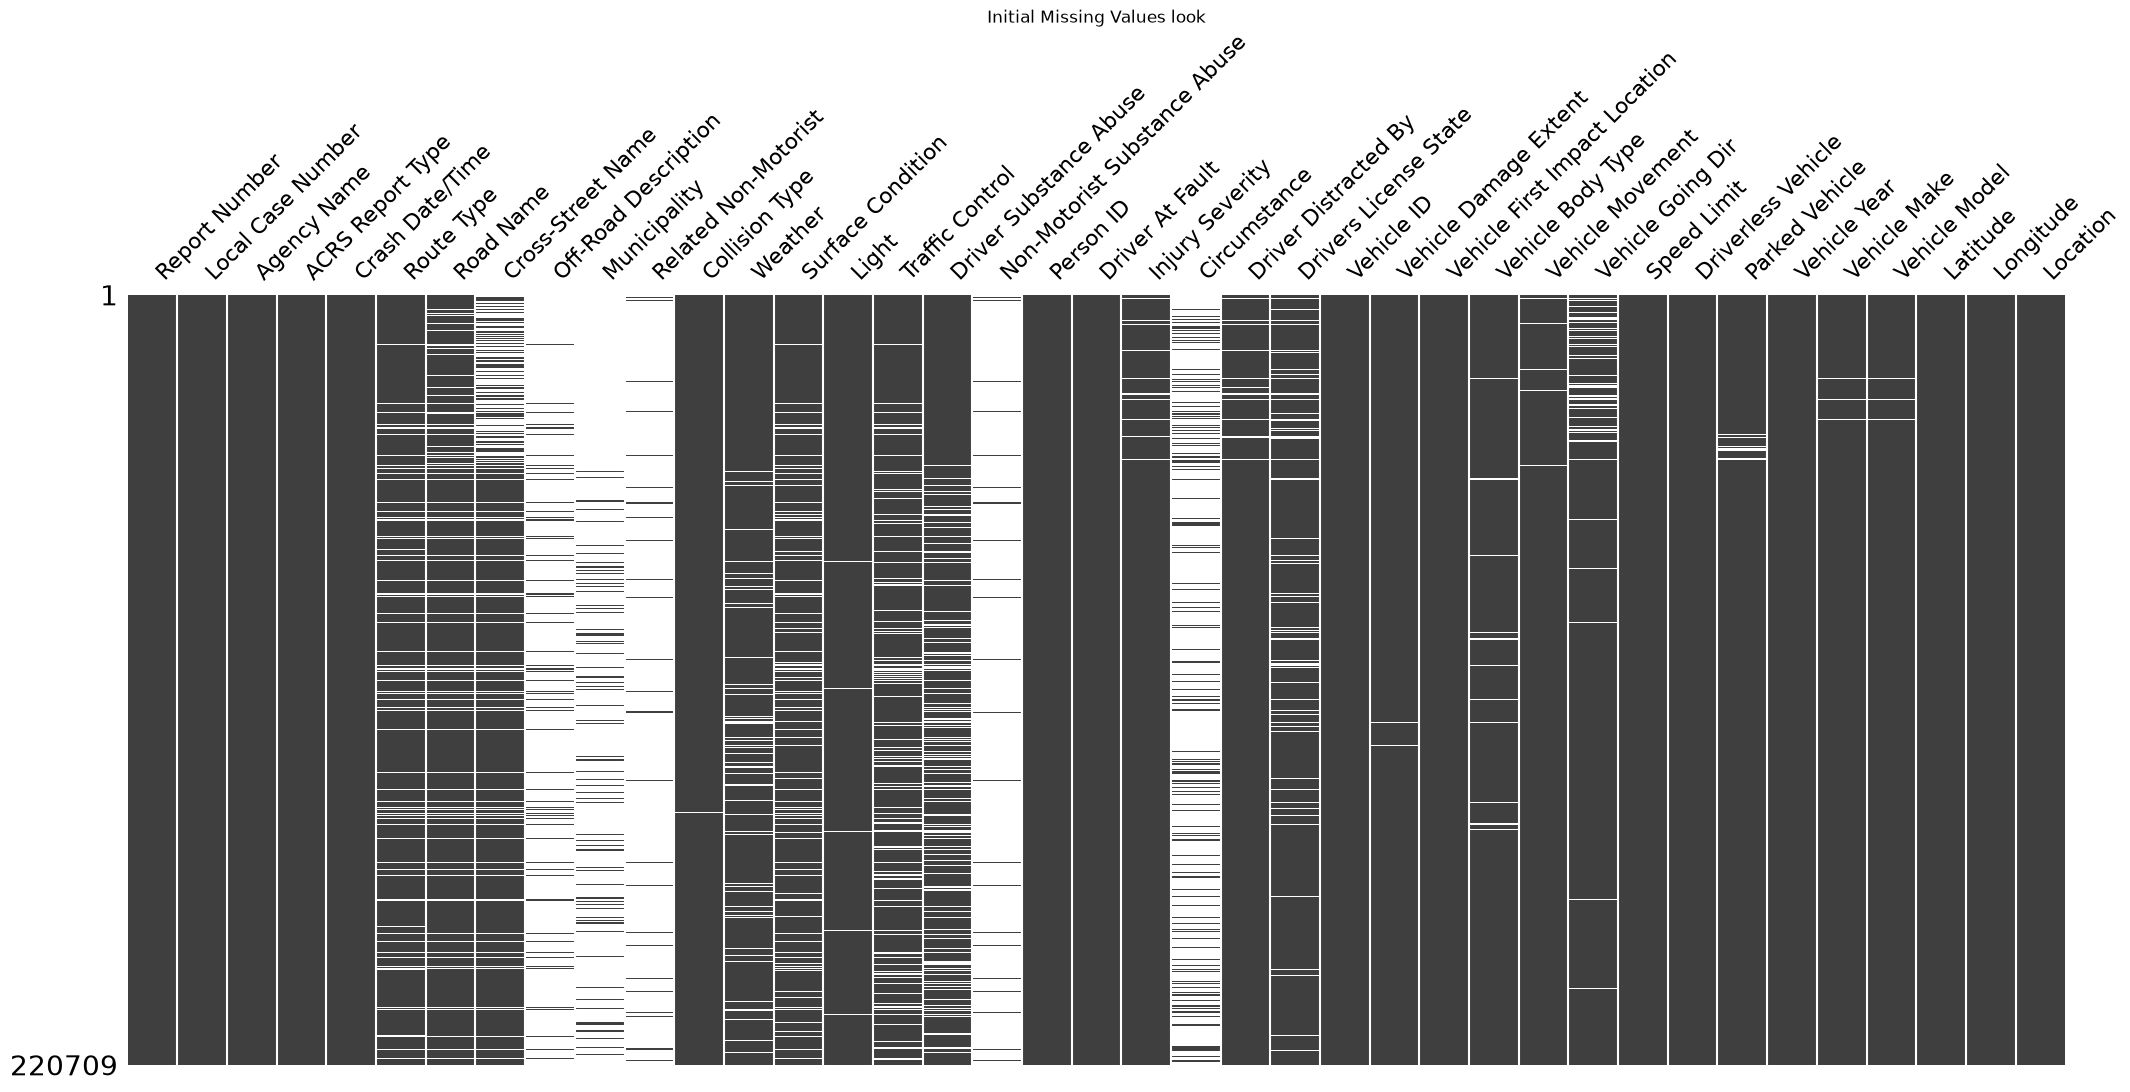

In [126]:
msno.matrix(df_clean, sparkline=False)
plt.title("Initial Missing Values look")
plt.show()

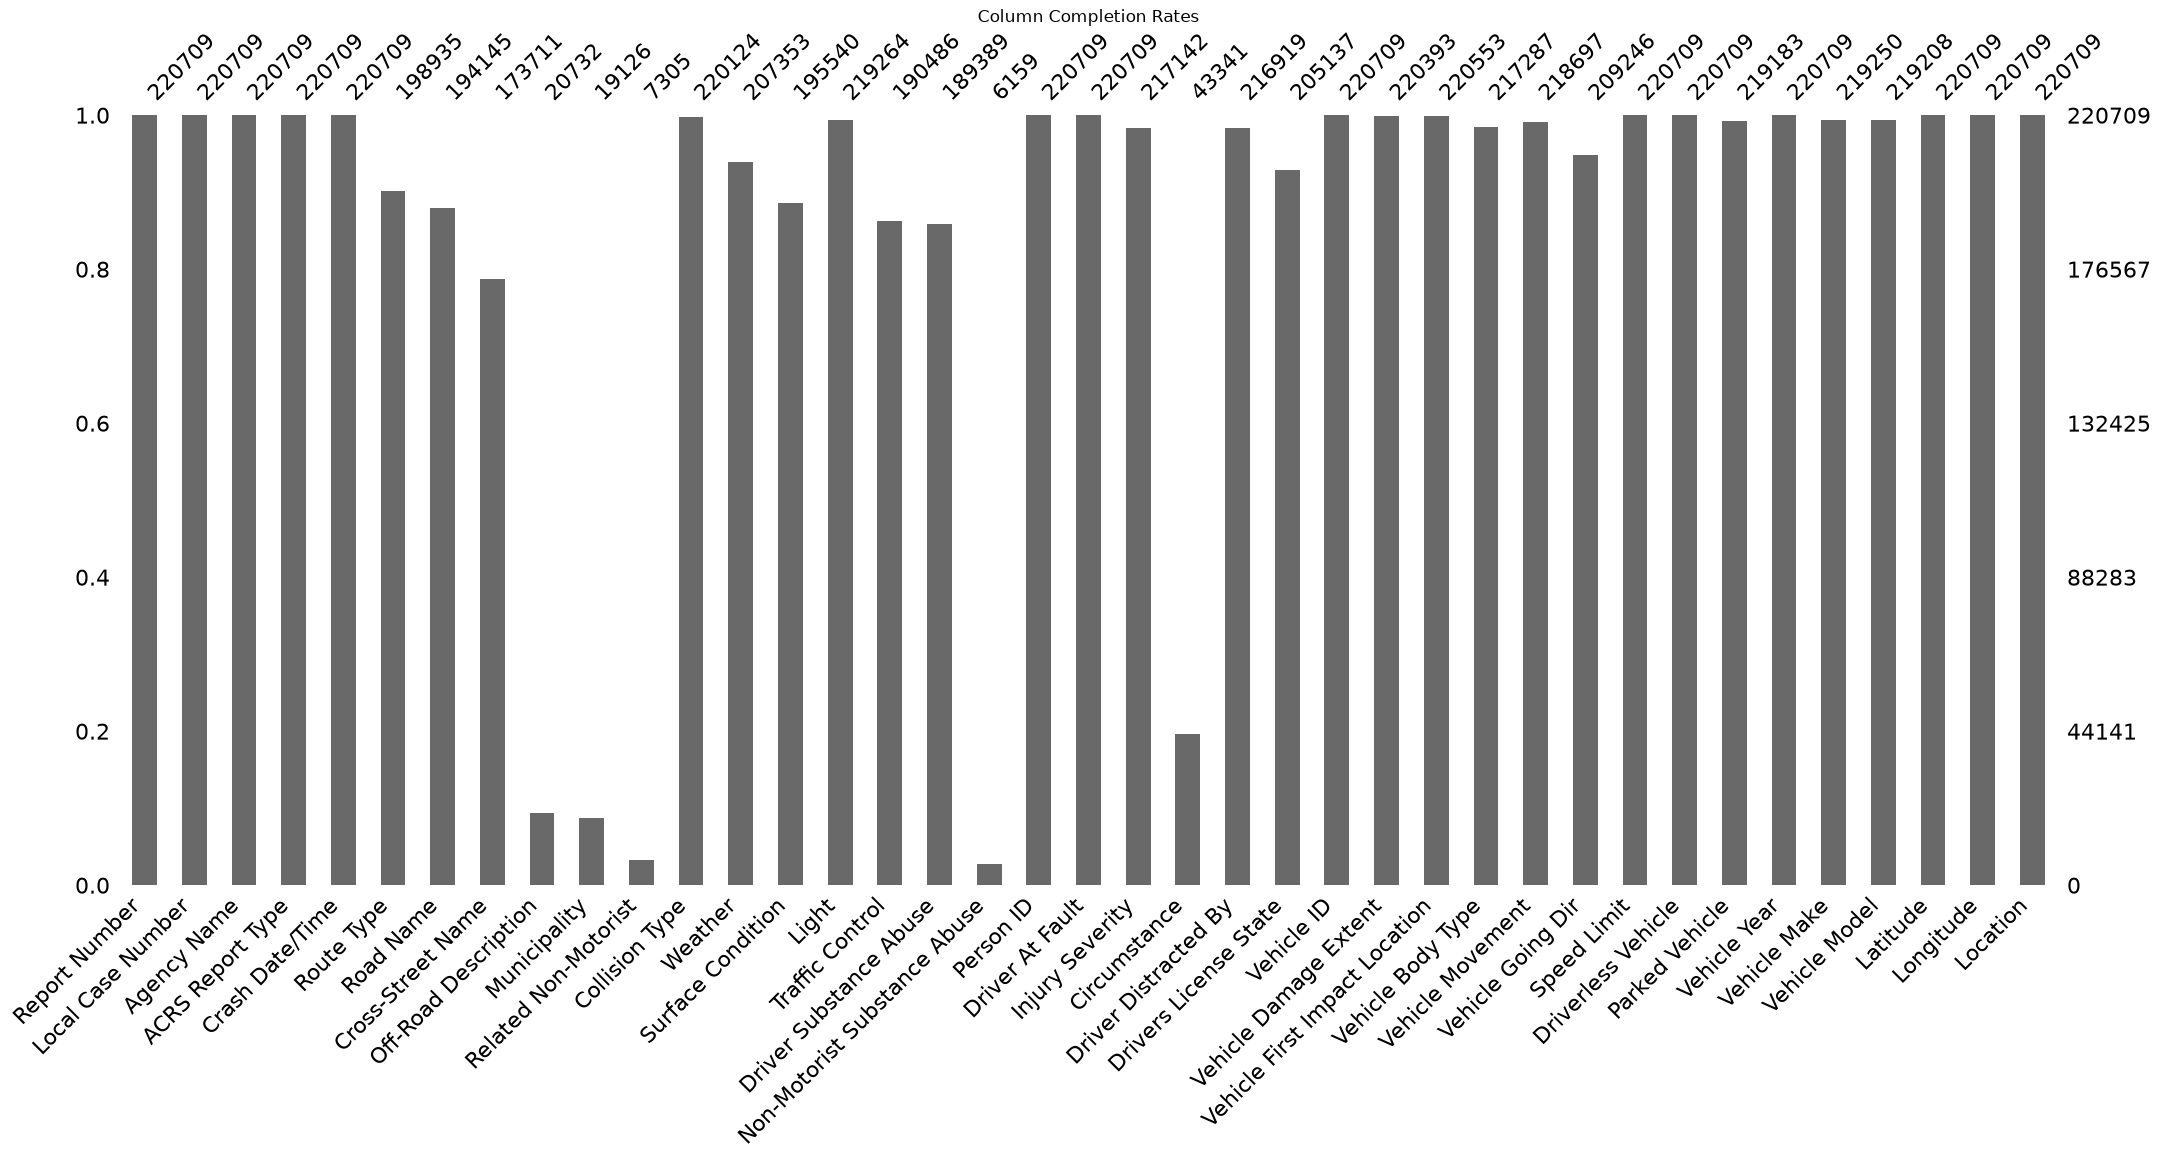

In [127]:
# Bar plot of overall completion rates
plt.figure(figsize=(10, 5))
msno.bar(df_clean)
plt.title("Column Completion Rates")
plt.show()

In [128]:
# Report missingness for every column
missing_report = pd.DataFrame({
    "Missing Count": df_clean.isna().sum(),
    "Missing Percent": df_clean.isna().mean().mul(100),
    "Non-Missing Count": df_clean.notna().sum()
})

missing_report = missing_report.sort_values(
    "Missing Percent",
    ascending=False
)

display(missing_report.round(2))

,Missing Count,Missing Percent,Non-Missing Count
Non-Motorist Substance Abuse,214550,97.21,6159
Related Non-Motorist,213404,96.69,7305
Municipality,201583,91.33,19126
Off-Road Description,199977,90.61,20732
Circumstance,177368,80.36,43341
Cross-Street Name,46998,21.29,173711
Driver Substance Abuse,31320,14.19,189389
Traffic Control,30223,13.69,190486
Road Name,26564,12.04,194145
Surface Condition,25169,11.40,195540


# Remove the requested columns and evaluate missingness
- removing `Cross-Street Name`, `Off-Road Description`, `Municipality`, `Related Non-Motorist`, `Non-Motorist Substance Abuse`, and `Circumstance` because over 50% of the data is missing

In [129]:
# Columns explicitly requested for removal
requested_drop = [
    "Cross-Street Name",
    "Off-Road Description",
    "Municipality",
    "Related Non-Motorist",
    "Non-Motorist Substance Abuse",
    "Circumstance"
]

# Drop only columns that actually exist
requested_drop = [
    col for col in requested_drop
    if col in df_clean.columns
]

df_clean = df_clean.drop(columns=requested_drop)

print("Requested columns removed:", requested_drop)
print("Shape after requested drops:", df_clean.shape)

# Missingness after requested columns are removed
missing_pct = df_clean.isna().mean().mul(100).sort_values(
    ascending=False
)

print("\nRemaining columns with the most missing values:")
display(missing_pct.head(20).to_frame("Missing Percent"))

# Identify columns above the review threshold
MISSING_THRESHOLD = 80

high_missing_cols = missing_pct[
    missing_pct > MISSING_THRESHOLD
].index.tolist()

print(
    f"\nColumns with more than {MISSING_THRESHOLD}% missing:"
)
print(high_missing_cols)

# Review these columns before deciding whether to drop them.
# Do not automatically remove important predictors or identifiers.

Requested columns removed: ['Cross-Street Name', 'Off-Road Description', 'Municipality', 'Related Non-Motorist', 'Non-Motorist Substance Abuse', 'Circumstance']
Shape after requested drops: (220709, 33)

Remaining columns with the most missing values:


,Missing Percent
Driver Substance Abuse,14.190631
Traffic Control,13.693597
Road Name,12.035757
Surface Condition,11.403704
Route Type,9.865479
Drivers License State,7.055444
Weather,6.051407
Vehicle Going Dir,5.193717
Driver Distracted By,1.717193
Injury Severity,1.616155



Columns with more than 80% missing:
[]


# Recommended columns to keep:
- Driver Substance Abuse
- Driver Distracted By
- Weather
- Surface Condition
- Light
- Traffic Control
- Collision Type

# Standardize injury severity and categorical variables

In [130]:
# Normalize labels for matching.
# Example: "Dark - Lighted" -> "dark lighted"
def normalize_label(value):
    if pd.isna(value):
        return np.nan

    value = str(value).strip().casefold()
    value = re.sub(r"[^a-z0-9]+", " ", value)
    return re.sub(r"\s+", " ", value).strip()


# Normalize all categorical/text labels for consistent formatting
text_cols = df_clean.select_dtypes(
    include=["object", "string"]
).columns

for col in text_cols:
    df_clean[col] = df_clean[col].map(
        lambda x: re.sub(r"\s+", " ", x).strip()
        if isinstance(x, str)
        else x
    )

# Standardize injury severity
severity_map = {
    "no apparent injury": "No Apparent Injury",
    "possible injury": "Possible Injury",
    "suspected minor injury": "Suspected Minor Injury",
    "suspected serious injury": "Suspected Serious Injury",
    "fatal injury": "Fatal Injury"
}

df_clean["Injury Severity"] = (
    df_clean["Injury Severity"]
    .map(normalize_label)
    .map(severity_map)
)

print("Standardized injury severity:")
print(df_clean["Injury Severity"].value_counts(dropna=False))

Standardized injury severity:
Injury Severity
No Apparent Injury          178405
Possible Injury              20709
Suspected Minor Injury       16016
NaN                           3567
Suspected Serious Injury      1806
Fatal Injury                   206
Name: count, dtype: int64


## Standardize weather, surface, lighting, and traffic control

In [131]:
def title_label(value):
    if pd.isna(value):
        return np.nan

    return normalize_label(value).title()


# Reusable mapping helper
def standardize_categories(series, mapping):
    normalized_mapping = {
        normalize_label(key): value
        for key, value in mapping.items()
    }

    normalized = series.map(normalize_label)

    return normalized.map(
        lambda x: normalized_mapping.get(x, title_label(x))
        if pd.notna(x)
        else np.nan
    )


# Weather
weather_map = {
    "clear": "Clear",
    "cloudy": "Cloudy",
    "rain": "Rain",
    "raining": "Rain",
    "Freezing Rain Or Freezing Drizzle": "Rain",
    "Blowing Snow": "Snow",
    "snow": "Snow",
    "sleet": "Sleet",
    "fog": "Fog",
    "foggy": "Fog",
    "Fog Smog Smoke": "Fog",
    "wintry mix": "Wintry Mix",
    "Severe Crosswinds": "Wind",
    "Severe Winds": "Wind",
    "wind": "Wind",
    "other": "Unknown",
    "unknown": "Unknown"
}

# Surface condition
surface_map = {
    "dry": "Dry",
    "wet": "Wet",
    "ice": "Ice",
    "ice frost": "Ice",
    "snow": "Snow",
    "slush": "Slush",
    "mud dirt gravel": "Mud/Dirt/Gravel",
    "water standing": "Wet",
    "Water Standing Moving": "Wet",
    "other": "Unknown",
    "unknown": "Unknown"
}

# Lighting
light_map = {
    "daylight": "Daylight",
    "dark lighted": "Dark - Lighted",
    "dark lights on": "Dark - Lighted",
    "dark not lighted": "Dark - Not Lighted",
    "dark no lights": "Dark - Not Lighted",
    "dark unknown lighting": "Dark - Unknown Lighting",
    "dawn": "Dawn",
    "dusk": "Dusk",
    "other": "Unknown",
    "unknown": "Unknown"
}

# Traffic control
traffic_map = {
    "no controls": "No Controls",
    "traffic signal": "Traffic Control Signal",
    "traffic control signal": "Traffic Control Signal",
    "stop sign": "Stop Sign",
    "yield sign": "Yield Sign",
    "flashing traffic signal": "Traffic Control Signal",
    "flashing traffic control signal": "Traffic Control Signal",
    "lane use control signal": "Lane Use Control Signal",
    "Pedestrian Crossing Sign": "Pedestrian Crossing",
    "Pedestrian Crossing": "Pedestrian Crossing",
    "person": "Person",
    "Other Signal": "Unknown",
    "other": "Unknown",
    "unknown": "Unknown"
}

category_mappings = {
    "Weather": weather_map,
    "Surface Condition": surface_map,
    "Light": light_map,
    "Traffic Control": traffic_map
}

for col, mapping in category_mappings.items():
    if col in df_clean.columns:
        df_clean[col] = standardize_categories(
            df_clean[col], mapping
        )

for col in category_mappings:
    if col in df_clean.columns:
        print(f"\n{col}:")
        print(df_clean[col].value_counts(dropna=False))


Weather:
Weather
Clear                     155083
Rain                       25453
Cloudy                     21666
NaN                        13356
Snow                        2108
Unknown                     1412
Fog                          798
Wintry Mix                   391
Sleet                        218
Wind                         190
Sleet Or Hail                 18
Blowing Sand Soil Dirt        16
Name: count, dtype: int64

Surface Condition:
Surface Condition
Dry                156606
Wet                 35123
NaN                 25169
Ice                  1320
Snow                 1294
Unknown               748
Slush                 353
Mud/Dirt/Gravel        57
Oil                    29
Sand                   10
Name: count, dtype: int64

Light:
Light
Daylight                   150375
Dark - Lighted              50511
Dark - Not Lighted           6614
Dusk                         4576
Dawn                         3945
Dark - Unknown Lighting      1844
NaN               

# Group collision types

In [132]:
collision_group = {
    # Head-on collisions
    "head on": "Head-on",
    "front to front": "Head-on",
    "head on left turn": "Head-on",
    "head on involving left turn": "Head-on",

    # Rear-end collisions
    "same dir rear end": "Rear-end",
    "front to rear": "Rear-end",
    "rear end same direction": "Rear-end",
    "same dir rend left turn": "Rear-end",
    "same dir rend right turn": "Rear-end",

    # Sideswipes
    "same direction sideswipe": "Sideswipe (same direction)",
    "sideswipe same direction": "Sideswipe (same direction)",
    "same direction right turn sideswipe": "Sideswipe (same direction)",
    "same direction left turn sideswipe": "Sideswipe (same direction)",
    "opposite direction sideswipe": "Sideswipe (opposite direction)",
    "sideswipe opposite direction": "Sideswipe (opposite direction)",

    # Turning / opposing left turns
    "opposite dir both left turn": "Opposing left turns",
    "opposite direction both left turn collision": "Opposing left turns",
    "angle meets left head on": "Opposing left turns",
    "same direction left turn": "Turning (same direction)",
    "same direction right turn": "Turning (same direction)",
    "same dir both left turn": "Turning (same direction)",
    "same direction both left turn collision": "Turning (same direction)",

    # Angle collisions
    "straight movement angle": "Angle",
    "angle": "Angle",
    "rear to side": "Angle",
    "angle meets left turn": "Angle",
    "angle collision involving left turn": "Angle",
    "angle meets right turn": "Angle",
    "angle collision involving right turn": "Angle",
    "angle head on involving left turn": "Angle",

    # Other collision types
    "rear to rear": "Rear to Rear",
    "single vehicle": "Single vehicle",
    "other": "Unknown",
    "unknown": "Unknown"
}

# Normalize keys for reliable matching
collision_group_normalized = {
    normalize_label(key): value
    for key, value in collision_group.items()
}

# Keep the standardized raw category
df_clean["Collision Type"] = df_clean["Collision Type"].map(
    lambda x: title_label(x) if pd.notna(x) else np.nan
)

collision_raw = df_clean["Collision Type"].map(normalize_label)

df_clean["Collision Group"] = collision_raw.map(
    collision_group_normalized
)

# Inspect unmapped categories before deciding what to do
unmapped = df_clean.loc[
    collision_raw.notna() & df_clean["Collision Group"].isna(),
    "Collision Type"
].value_counts()

print("Unmapped collision types:")
print(unmapped)

print("\nCollision group counts:")
print(df_clean["Collision Group"].value_counts(dropna=False))

Unmapped collision types:
Series([], Name: count, dtype: int64)

Collision group counts:
Collision Group
Rear-end                          71600
Angle                             46022
Sideswipe (same direction)        24020
Unknown                           22938
Single vehicle                    21628
Head-on                           19416
Turning (same direction)           8266
Sideswipe (opposite direction)     4646
Opposing left turns                1022
NaN                                 585
Rear to Rear                        566
Name: count, dtype: int64


# Harmonize category labels that changed in 2024
Starting in 2024 the source data uses different labels for several fields, for example:

| Field | 2022-2023 | 2024+ |
|---|---|---|
| Vehicle Body Type | `PASSENGER CAR`, `(SPORT) UTILITY VEHICLE` | `Passenger Car`, `Sport Utility Vehicle` |
| Vehicle Movement | `MOVING CONSTANT SPEED`, `MAKING LEFT TURN` | `Moving Constant Speed`, `Turning Left` |
| Vehicle Going Dir | `North`, `East` | `Northbound`, `Eastbound` |
| Route Type | `County`, `Maryland (State)` | `County Route`, `Maryland (State) Route` |

Before this step, only 5 of 33 body-type labels matched across the two periods, so models trained on 2022-2023 could not use these features on 2024-2025 data. This cell maps the old labels onto the 2024+ wording and prints any label that still appears in only one period.

Judgment calls:
- Body types are grouped into 9 broad types (Passenger Car, SUV, Pickup, Van, Bus, Truck, Motorcycle/Moped, Other, Unknown) because the two schemes split vehicles differently.
- Police, fire, and ambulance exist only before 2024 (afterwards they are recorded by body style), so they are grouped as Other.
- Dropped movement labels go to their closest new label: "Starting From Lane" becomes Accelerating, "Starting From Parked" becomes Entering Traffic Lane, and "Parking" becomes Leaving Traffic Lane.
- Weather "Sleet", "Wintry Mix", and "Sleet Or Hail" are merged; the new detailed warning-sign and school-zone traffic controls are merged back into the older broad categories.
- **Not changed:** Collision Group (from the mapping above) still has "Turning (same direction)" and "Opposing left turns" only before 2024, and "Rear to Rear" only after. The underlying Collision Type scheme changed too, and there is no clean one-to-one mapping.

In [133]:
# Starting in 2024, Montgomery County changed the category labels for
# several fields (e.g. "PASSENGER CAR" -> "Passenger Car",
# "North" -> "Northbound", "County" -> "County Route").
# Without this step, a model trained on 2022-2023 sees the 2024+ labels
# as unknown categories. All labels are mapped onto the 2024+ wording.
# standardize_categories() and normalize_label() come from the cells above,
# so keys are matched regardless of case and punctuation.

body_type_map = {
    # Cars
    "passenger car": "Passenger Car",
    "station wagon": "Passenger Car",
    "limousine": "Passenger Car",

    # SUVs and pickups
    "(sport) utility vehicle": "Sport Utility Vehicle",
    "sport utility vehicle": "Sport Utility Vehicle",
    "pickup truck": "Pickup",
    "pickup": "Pickup",

    # Vans (passenger and light cargo)
    "van": "Van",
    "van - passenger (<9 seats)": "Van",
    "van - passenger (&lt;9 seats)": "Van",
    "van - passenger (9 or 12 seats)": "Van",
    "van - passenger (15 seats)": "Van",
    "van - cargo": "Van",

    # Buses
    "transit bus": "Bus",
    "school bus": "Bus",
    "other bus": "Bus",
    "cross country bus": "Bus",
    "bus - transit": "Bus",
    "bus - school": "Bus",
    "bus - other type": "Bus",
    "bus - mini": "Bus",
    "bus - cross country": "Bus",

    # Trucks
    "cargo van/light truck 2 axles (over 10,000lbs (4,536 kg))": "Truck",
    "other light trucks (10,000lbs (4,536kg) or less)": "Truck",
    "medium/heavy trucks 3 axles (over 10,000lbs (4,536kg))": "Truck",
    "truck tractor": "Truck",
    "other trucks": "Truck",
    "single-unit truck": "Truck",

    # Motorcycles and mopeds
    "motorcycle": "Motorcycle/Moped",
    "motorcycle - 2 wheeled": "Motorcycle/Moped",
    "motorcycle - 3 wheeled": "Motorcycle/Moped",
    "moped": "Motorcycle/Moped",
    "moped or motorized bicycle": "Motorcycle/Moped",
    "autocycle": "Motorcycle/Moped",

    # Police, fire, and ambulance only exist before 2024.
    # After 2024 these vehicles are recorded by body style instead,
    # so they cannot be matched and are grouped as Other.
    "police vehicle/non emergency": "Other",
    "police vehicle/emergency": "Other",
    "ambulance/emergency": "Other",
    "ambulance/non emergency": "Other",
    "fire vehicle/emergency": "Other",
    "fire vehicle/non emergency": "Other",

    # Rare special vehicles
    "recreational vehicle": "Other",
    "motor home": "Other",
    "snowmobile": "Other",
    "all terrain vehicle (atv)": "Other",
    "all-terrain vehicle/all-terrain cycle (atv/atc)": "Other",
    "recreational off-highway vehicles (rov)": "Other",
    "low speed vehicle": "Other",
    "golf cart": "Other",
    "farm vehicle": "Other",
    "farm equipment (tractor, combine harvester, etc.)": "Other",
    "construction equipment (backhoe, bulldozer, etc.)": "Other",
    "other": "Other",

    "unknown": "Unknown"
}

movement_map = {
    "moving constant speed": "Moving Constant Speed",
    "slowing or stopping": "Slowing or Stopping",
    "stopped in traffic lane": "Stopped in Traffic",
    "stopped in traffic": "Stopped in Traffic",
    "making left turn": "Turning Left",
    "turning left": "Turning Left",
    "making right turn": "Turning Right",
    "right turn on red": "Turning Right",
    "turning right": "Turning Right",
    "making u turn": "Making U-Turn",
    "making u-turn": "Making U-Turn",
    "passing": "Overtaking/Passing",
    "overtaking/passing": "Overtaking/Passing",
    "accelerating": "Accelerating",
    # Closest 2024+ equivalents for labels that were dropped
    "starting from lane": "Accelerating",
    "starting from parked": "Entering Traffic Lane",
    "parking": "Leaving Traffic Lane",
    "entering traffic lane": "Entering Traffic Lane",
    "leaving traffic lane": "Leaving Traffic Lane",
    "changing lanes": "Changing Lanes",
    "backing": "Backing",
    "parked": "Parked",
    "negotiating a curve": "Negotiating a Curve",
    "skidding": "Other",
    "driverless moving veh.": "Other",
    "other": "Other",
    "unknown": "Unknown"
}

direction_map = {
    "north": "Northbound",
    "south": "Southbound",
    "east": "Eastbound",
    "west": "Westbound",
    "northbound": "Northbound",
    "southbound": "Southbound",
    "eastbound": "Eastbound",
    "westbound": "Westbound",
    "not on roadway": "Not On Roadway",
    "unknown": "Unknown"
}

route_map = {
    "county": "County Route",
    "county route": "County Route",
    "maryland (state)": "Maryland (State) Route",
    "maryland (state) route": "Maryland (State) Route",
    "municipality": "Municipality Route",
    "municipality route": "Municipality Route",
    "government": "Government Route",
    "government route": "Government Route",
    "us (state)": "US (State)",
    "interstate (state)": "Interstate (State)",
    "other public roadway": "Other Public Roadway",
    "unknown": "Unknown"
}

# Weather and Traffic Control were standardized above, but 2024+ splits
# a few of their categories more finely. Merge those back together.
weather_harmonize_map = {
    "sleet": "Sleet/Wintry Mix",
    "wintry mix": "Sleet/Wintry Mix",
    "sleet or hail": "Sleet/Wintry Mix"
}

traffic_harmonize_map = {
    "warning sign": "Warning Sign",
    "intersection ahead warning sign": "Warning Sign",
    "curve ahead warning sign": "Warning Sign",
    "reduce speed ahead warning sign": "Warning Sign",
    "other warning sign": "Warning Sign",
    "school zone sign device": "School Zone Sign",
    "school zone sign": "School Zone Sign",
    "school zone": "School Zone Sign",
    "railway crossing device": "Railroad Crossing",
    "railroad crossing": "Railroad Crossing",
    "flashing railroad crossing signal may include gates": "Railroad Crossing",
    "person including flagger law enforcement crossing guard etc": "Person",
    "ramp meter signal": "Traffic Control Signal",
    "bicycle crossing sign": "Pedestrian Crossing",
    "other pavement marking excluding edgelines centerlines or lane lines": "Other"
}

harmonize_mappings = {
    "Vehicle Body Type": body_type_map,
    "Vehicle Movement": movement_map,
    "Vehicle Going Dir": direction_map,
    "Route Type": route_map,
    "Weather": weather_harmonize_map,
    "Traffic Control": traffic_harmonize_map
}

for col, mapping in harmonize_mappings.items():
    if col in df_clean.columns:
        df_clean[col] = standardize_categories(df_clean[col], mapping)

# Check: list any label that appears in only one of the two periods.
crash_year = df_clean["Crash Date/Time"].dt.year
before_2024 = crash_year.between(2022, 2023)
from_2024 = crash_year >= 2024

for col in list(harmonize_mappings) + ["Collision Group"]:
    old_counts = df_clean.loc[before_2024, col].value_counts()
    new_counts = df_clean.loc[from_2024, col].value_counts()

    only_old = old_counts[~old_counts.index.isin(new_counts.index)]
    only_new = new_counts[~new_counts.index.isin(old_counts.index)]

    print(f"\n{col}: {len(old_counts)} labels in 2022-2023, "
          f"{len(new_counts)} labels in 2024+")
    if len(only_old):
        print("  Only in 2022-2023:", only_old.to_dict())
    if len(only_new):
        print("  Only in 2024+:", only_new.to_dict())


Vehicle Body Type: 9 labels in 2022-2023, 10 labels in 2024+
  Only in 2024+: {'Large Limo': 1}

Vehicle Movement: 16 labels in 2022-2023, 14 labels in 2024+
  Only in 2022-2023: {'Unknown': 717, 'Other': 282}

Vehicle Going Dir: 5 labels in 2022-2023, 6 labels in 2024+
  Only in 2024+: {'Not On Roadway': 2917}

Route Type: 10 labels in 2022-2023, 14 labels in 2024+
  Only in 2022-2023: {'Unknown': 3}
  Only in 2024+: {'Local Route': 948, 'Bicycle Route': 543, 'Spur': 458, 'Private Route': 350, 'Crossover': 305}

Weather: 8 labels in 2022-2023, 9 labels in 2024+
  Only in 2024+: {'Blowing Sand Soil Dirt': 1}

Traffic Control: 9 labels in 2022-2023, 13 labels in 2024+
  Only in 2024+: {'Pedestrian Crossing': 464, 'Lane Use Control Signal': 308, 'Other': 153, 'Flashing School Zone Signal': 1}

Collision Group: 9 labels in 2022-2023, 8 labels in 2024+
  Only in 2022-2023: {'Turning (same direction)': 1887, 'Opposing left turns': 202}
  Only in 2024+: {'Rear to Rear': 566}


# Convert numeric fields and check invalid values

In [134]:
numeric_cols = [
    "Speed Limit",
    "Vehicle Year",
    "Latitude",
    "Longitude"
]

for col in numeric_cols:
    if col in df_clean.columns:
        df_clean[col] = pd.to_numeric(
            df_clean[col], errors="coerce"
        )

# Flag impossible or suspicious values rather than deleting blindly
if "Speed Limit" in df_clean.columns:
    print("Speed limit distribution:")
    print(df_clean["Speed Limit"].describe())

    print(
        "Nonpositive speed limits:",
        (df_clean["Speed Limit"].notna() &
         (df_clean["Speed Limit"] <= 0)).sum()
    )

if "Vehicle Year" in df_clean.columns:
    print("Vehicle year distribution:")
    print(df_clean["Vehicle Year"].describe())

if {"Latitude", "Longitude"}.issubset(df_clean.columns):
    invalid_coordinates = (
        df_clean["Latitude"].notna()
        & ~df_clean["Latitude"].between(-90, 90)
    ) | (
        df_clean["Longitude"].notna()
        & ~df_clean["Longitude"].between(-180, 180)
    )

    print("Invalid coordinate rows:", invalid_coordinates.sum())

Speed limit distribution:
count    220709.000000
mean         32.003090
std          11.443303
min           0.000000
25%          25.000000
50%          35.000000
75%          40.000000
max          75.000000
Name: Speed Limit, dtype: float64
Nonpositive speed limits: 9656
Vehicle year distribution:
count    220709.000000
mean       1964.372826
std         345.519846
min           0.000000
25%        2007.000000
50%        2012.000000
75%        2016.000000
max        9999.000000
Name: Vehicle Year, dtype: float64
Invalid coordinate rows: 0


# Remove exact duplicates and filter to 2022–2025

In [135]:
# Remove exact duplicate rows only
duplicates_before = df_clean.duplicated().sum()

df_clean = df_clean.drop_duplicates().copy()

print("Exact duplicates removed:", duplicates_before)
print("Shape after duplicate removal:", df_clean.shape)

# Exclude records with invalid/missing dates because the
# requested study period cannot be determined for those rows
valid_dates = df_clean["Crash Date/Time"].notna()

df_2022_2025 = df_clean.loc[
    valid_dates
    & df_clean["Crash Date/Time"].ge(
        pd.Timestamp("2022-01-01")
    )
    & df_clean["Crash Date/Time"].lt(
        pd.Timestamp("2026-01-01")
    )
].copy()

print("Shape after date filtering:", df_2022_2025.shape)
print(
    "Date range:",
    df_2022_2025["Crash Date/Time"].min(),
    "to",
    df_2022_2025["Crash Date/Time"].max()
)

print("\nRecords per year:")
print(
    df_2022_2025["Crash Date/Time"]
    .dt.year.value_counts()
    .sort_index()
)

Exact duplicates removed: 0
Shape after duplicate removal: (220709, 34)
Shape after date filtering: (73077, 34)
Date range: 2022-01-01 00:34:00 to 2025-12-31 22:50:00

Records per year:
Crash Date/Time
2022    17582
2023    18929
2024    18600
2025    17966
Name: count, dtype: int64


# Create time-based features

In [136]:
dt = df_2022_2025["Crash Date/Time"]

# Calendar features
df_2022_2025["Crash Year"] = dt.dt.year
df_2022_2025["Crash Month"] = dt.dt.month
df_2022_2025["Crash Day"] = dt.dt.day
df_2022_2025["Crash Hour"] = dt.dt.hour

# Monday = 0, Sunday = 6
df_2022_2025["Crash Day of Week"] = dt.dt.dayofweek

# Weekend indicator
df_2022_2025["Is Weekend"] = (
    df_2022_2025["Crash Day of Week"] >= 5
).astype("int8")

# Time of day
def get_time_period(hour):
    if pd.isna(hour):
        return np.nan
    elif 5 <= hour < 12:
        return "Morning"
    elif 12 <= hour < 17:
        return "Afternoon"
    elif 17 <= hour < 21:
        return "Evening"
    else:
        return "Night"

df_2022_2025["Crash Time Period"] = (
    df_2022_2025["Crash Hour"].map(get_time_period)
)

# Optional: rush-hour indicator, using a simple weekday definition
hour = df_2022_2025["Crash Hour"]
weekday = df_2022_2025["Crash Day of Week"] < 5

df_2022_2025["Is Weekday Rush Hour"] = (
    weekday
    & (
        hour.between(7, 9)
        | hour.between(16, 18)
    )
).astype("int8")

# Optional: season
season_map = {
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Spring", 4: "Spring", 5: "Spring",
    6: "Summer", 7: "Summer", 8: "Summer",
    9: "Fall", 10: "Fall", 11: "Fall"
}

df_2022_2025["Crash Season"] = (
    df_2022_2025["Crash Month"].map(season_map)
)

print("Time-based features created.")
display(
    df_2022_2025[
        [
            "Crash Date/Time",
            "Crash Year",
            "Crash Month",
            "Crash Hour",
            "Crash Day of Week",
            "Is Weekend",
            "Crash Time Period",
            "Is Weekday Rush Hour",
            "Crash Season"
        ]
    ].head()
)

Time-based features created.


C:\Users\chris\AppData\Local\Temp\ipykernel_17856\3301105028.py:10: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df_2022_2025["Crash Day of Week"] = dt.dt.dayofweek


,Crash Date/Time,Crash Year,Crash Month,Crash Hour,Crash Day of Week,Is Weekend,Crash Time Period,Is Weekday Rush Hour,Crash Season
12027,2025-12-31 22:50:00,2025,12,22,2,0,Night,0,Winter
12028,2025-12-31 21:54:00,2025,12,21,2,0,Night,0,Winter
12029,2025-12-31 21:54:00,2025,12,21,2,0,Night,0,Winter
12030,2025-12-31 21:40:00,2025,12,21,2,0,Night,0,Winter
12031,2025-12-31 21:40:00,2025,12,21,2,0,Night,0,Winter


# Reassess missing values and decide what to retain

In [137]:
missing_after_filter = pd.DataFrame({
    "Missing Count": df_2022_2025.isna().sum(),
    "Missing Percent": (
        df_2022_2025.isna().mean() * 100
    ).round(2),
    "Unique Values": df_2022_2025.nunique(dropna=True)
}).sort_values("Missing Percent", ascending=False)

print("Missingness after filtering to 2022–2025:")
display(missing_after_filter)

# Save the missingness report for documentation
missing_after_filter.to_csv(
    "missingness_report_2022_2025.csv"
)

# Check the main predictors and target
important_cols = [
    "Injury Severity",
    "Collision Type",
    "Collision Group",
    "Weather",
    "Surface Condition",
    "Light",
    "Traffic Control",
    "Driver Substance Abuse",
    "Driver Distracted By",
    "Speed Limit",
    "Vehicle Body Type",
    "Crash Hour",
    "Crash Day of Week",
    "Crash Month"
]

important_cols = [
    col for col in important_cols
    if col in df_2022_2025.columns
]

display(missing_after_filter.loc[important_cols])

Missingness after filtering to 2022–2025:


,Missing Count,Missing Percent,Unique Values
Road Name,11365,15.55,3264
Traffic Control,7844,10.73,12
Surface Condition,7756,10.61,9
Route Type,7167,9.81,15
Drivers License State,7077,9.68,74
Vehicle Going Dir,7050,9.65,6
Driver Substance Abuse,6625,9.07,20
Weather,2701,3.70,8
Driver Distracted By,2681,3.67,24
Injury Severity,2493,3.41,5


,Missing Count,Missing Percent,Unique Values
Injury Severity,2493,3.41,5
Collision Type,132,0.18,25
Collision Group,132,0.18,10
Weather,2701,3.70,8
Surface Condition,7756,10.61,9
Light,291,0.40,7
Traffic Control,7844,10.73,12
Driver Substance Abuse,6625,9.07,20
Driver Distracted By,2681,3.67,24
Speed Limit,0,0.00,16


# Validate the cleaned dataset
- checks the target distribution, remaining duplicates, category mappings, and the date filter

In [138]:
print("=" * 55)
print("FINAL CLEANING SUMMARY")
print("=" * 55)

print("\nDataset shape:", df_2022_2025.shape)

print("\nDate range:")
print(df_2022_2025["Crash Date/Time"].min())
print(df_2022_2025["Crash Date/Time"].max())

print("\nRecords per year:")
print(
    df_2022_2025["Crash Year"]
    .value_counts()
    .sort_index()
)

print("\nInjury severity distribution:")
print(
    df_2022_2025["Injury Severity"]
    .value_counts(dropna=False)
)

print("\nInjury severity proportions (%):")
print(
    df_2022_2025["Injury Severity"]
    .value_counts(normalize=True, dropna=False)
    .mul(100)
    .round(2)
)

print("\nMissing target values:")
print(df_2022_2025["Injury Severity"].isna().sum())

print("\nExact duplicate rows:")
print(df_2022_2025.duplicated().sum())

print("\nCollision groups:")
print(
    df_2022_2025["Collision Group"]
    .value_counts(dropna=False)
)

print("\nMissing values in time-based features:")
time_features = [
    "Crash Year",
    "Crash Month",
    "Crash Hour",
    "Crash Day of Week",
    "Is Weekend",
    "Crash Time Period",
    "Is Weekday Rush Hour",
    "Crash Season"
]

print(df_2022_2025[time_features].isna().sum())

# Assertions for the study period
assert df_2022_2025["Crash Date/Time"].notna().all()
assert df_2022_2025["Crash Date/Time"].ge(
    pd.Timestamp("2022-01-01")
).all()
assert df_2022_2025["Crash Date/Time"].lt(
    pd.Timestamp("2026-01-01")
).all()

print("\nDate filter verification passed.")

FINAL CLEANING SUMMARY

Dataset shape: (73077, 43)

Date range:
2022-01-01 00:34:00
2025-12-31 22:50:00

Records per year:
Crash Year
2022    17582
2023    18929
2024    18600
2025    17966
Name: count, dtype: int64

Injury severity distribution:
Injury Severity
No Apparent Injury          58663
Possible Injury              6032
Suspected Minor Injury       5257
NaN                          2493
Suspected Serious Injury      557
Fatal Injury                   75
Name: count, dtype: int64

Injury severity proportions (%):
Injury Severity
No Apparent Injury          80.28
Possible Injury              8.25
Suspected Minor Injury       7.19
NaN                          3.41
Suspected Serious Injury     0.76
Fatal Injury                 0.10
Name: proportion, dtype: float64

Missing target values:
2493

Exact duplicate rows:
0

Collision groups:
Collision Group
Rear-end                          21750
Angle                             17064
Sideswipe (same direction)         9585
Single vehi

# Prepare the modeling dataset and save the output
- `df_2022_2025`: your cleaned study dataset, including rows with missing injury severity. Use it for descriptive analyses where appropriate.

- `df_model`: the subset with known injury severity, ready for a supervised classification workflow.
  - **NOTE**: `df_model` already removes rows with missing values in Injury Severity only

In [139]:
# Keep the full cleaned study dataset for descriptive analysis
df_2022_2025.to_csv(
    "montgomery_crashes_cleaned_2022_2025.csv",
    index=False
)

# Create a labeled dataset for supervised modeling
df_model = df_2022_2025.loc[
    df_2022_2025["Injury Severity"].notna()
].copy()

print("Cleaned study dataset:", df_2022_2025.shape)
print("Labeled modeling dataset:", df_model.shape)
print(
    "Rows excluded due to missing target:",
    len(df_2022_2025) - len(df_model)
)

df_model.to_csv(
    "montgomery_crashes_modeling_2022_2025.csv",
    index=False
)

print("\nCleaned files saved successfully.")

Cleaned study dataset: (73077, 43)
Labeled modeling dataset: (70584, 43)
Rows excluded due to missing target: 2493

Cleaned files saved successfully.


# Verify the filtered dataset
- `df_2022_2025` becomes the main dataset for EDA and modeling.
  - **NOTE**: `df_2022_2025` STILL INCLUDES rows with missing values in injury severity

In [140]:
# 1. Check dataset size
print("Filtered dataset shape:", df_2022_2025.shape)

# 2. Check date range and invalid dates
print("\nDate range:")
print(df_2022_2025["Crash Date/Time"].min())
print(df_2022_2025["Crash Date/Time"].max())

print(
    "Missing dates:",
    df_2022_2025["Crash Date/Time"].isna().sum()
)

# 3. Check records per year
print("\nRecords per year:")
print(
    df_2022_2025["Crash Date/Time"]
    .dt.year.value_counts()
    .sort_index()
)

# 4. Check injury severity
print("\nInjury severity distribution:")
print(
    df_2022_2025["Injury Severity"]
    .value_counts(dropna=False)
)

print(
    "\nMissing injury severity:",
    df_2022_2025["Injury Severity"].isna().sum()
)

# 5. Check duplicate rows
print(
    "\nDuplicate rows:",
    df_2022_2025.duplicated().sum()
)

# 6. Check collision groups
print("\nCollision groups:")
print(
    df_2022_2025["Collision Group"]
    .value_counts(dropna=False)
)

# 7. Verify time-based features
time_features = [
    "Crash Hour",
    "Crash Day of Week",
    "Crash Month"
]

print("\nTime feature missing values:")
print(df_2022_2025[time_features].isna().sum())

# 8. Confirm date filter
assert df_2022_2025["Crash Date/Time"].notna().all()
assert df_2022_2025["Crash Date/Time"].ge(
    pd.Timestamp("2022-01-01")
).all()
assert df_2022_2025["Crash Date/Time"].lt(
    pd.Timestamp("2026-01-01")
).all()

print("\nDate and target verification passed.")

Filtered dataset shape: (73077, 43)

Date range:
2022-01-01 00:34:00
2025-12-31 22:50:00
Missing dates: 0

Records per year:
Crash Date/Time
2022    17582
2023    18929
2024    18600
2025    17966
Name: count, dtype: int64

Injury severity distribution:
Injury Severity
No Apparent Injury          58663
Possible Injury              6032
Suspected Minor Injury       5257
NaN                          2493
Suspected Serious Injury      557
Fatal Injury                   75
Name: count, dtype: int64

Missing injury severity: 2493

Duplicate rows: 0

Collision groups:
Collision Group
Rear-end                          21750
Angle                             17064
Sideswipe (same direction)         9585
Single vehicle                     7572
Unknown                            6732
Head-on                            5728
Sideswipe (opposite direction)     1983
Turning (same direction)           1887
Rear to Rear                        442
Opposing left turns                 202
NaN            

# EDA (NO IMPUTATION HAS BEEN PERFORMED YET)

## Target Distribution from 2022-2025

Injury Severity
No Apparent Injury          58663
Possible Injury              6032
Suspected Minor Injury       5257
Suspected Serious Injury      557
Fatal Injury                   75
Name: count, dtype: int64

Percentages:
Injury Severity
No Apparent Injury          80.28
Possible Injury              8.25
Suspected Minor Injury       7.19
Suspected Serious Injury     0.76
Fatal Injury                 0.10
Name: count, dtype: float64


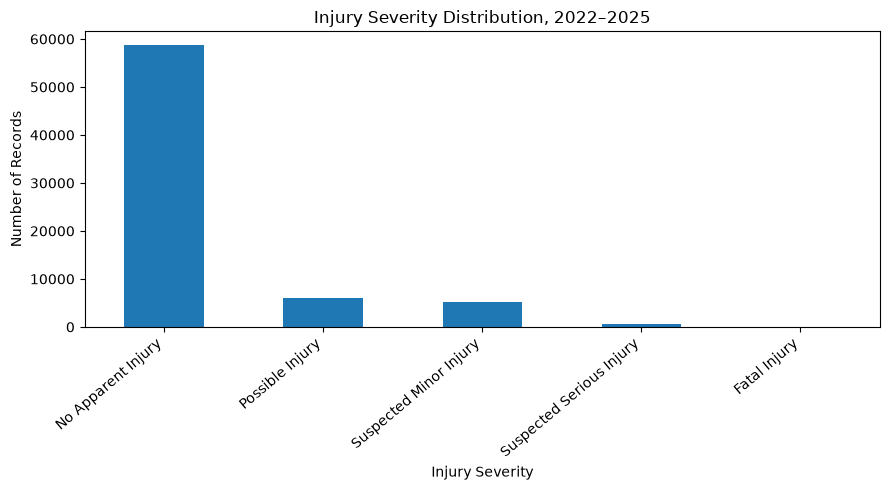

In [141]:
target_counts = df_2022_2025["Injury Severity"].value_counts()

print(target_counts)
print("\nPercentages:")
print(
    (target_counts / len(df_2022_2025) * 100).round(2)
)

target_counts.plot(kind="bar", figsize=(9, 5))
plt.title("Injury Severity Distribution, 2022–2025")
plt.xlabel("Injury Severity")
plt.ylabel("Number of Records")
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.show()

## Record how many target labels are missing

In [142]:
# Record how many target labels are missing
missing_target = df_2022_2025["Injury Severity"].isna().sum()

print("Rows with missing Injury Severity:", missing_target)

Rows with missing Injury Severity: 2493


## Examine missing values
- **What to look for**: Which potentially useful features have lots of missing values? Missing values can limit the information available for analysis and modeling. Don't automatically delete every column with missing data; decide based on its usefulness and how much information is missing.

,Missing Count,Missing Percent
Road Name,11365,15.55
Traffic Control,7844,10.73
Surface Condition,7756,10.61
Route Type,7167,9.81
Drivers License State,7077,9.68
Vehicle Going Dir,7050,9.65
Driver Substance Abuse,6625,9.07
Weather,2701,3.70
Driver Distracted By,2681,3.67
Injury Severity,2493,3.41


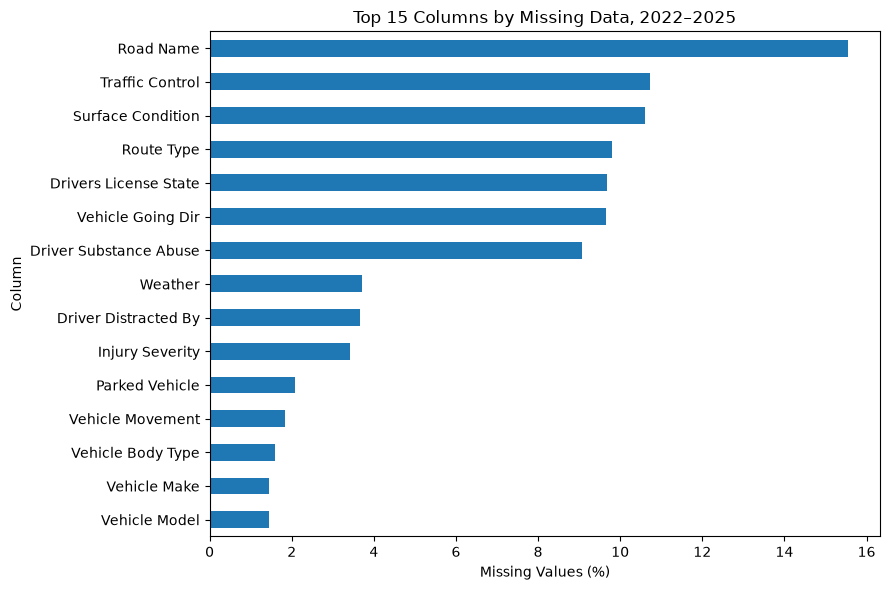

In [143]:
# Missing values in the filtered EDA dataset
missing_summary = pd.DataFrame({
    "Missing Count": df_2022_2025.isna().sum(),
    "Missing Percent": (
        df_2022_2025.isna().mean() * 100
    ).round(2)
})

missing_summary = missing_summary.sort_values(
    "Missing Percent", ascending=False
)

display(missing_summary.head(20))

# Visualize the 15 columns with the most missing data
top_missing = missing_summary[
    missing_summary["Missing Count"] > 0
].head(15)

top_missing["Missing Percent"].sort_values().plot(
    kind="barh", figsize=(9, 6)
)

plt.title("Top 15 Columns by Missing Data, 2022–2025")
plt.xlabel("Missing Values (%)")
plt.ylabel("Column")
plt.tight_layout()
plt.show()

# Compare injury severity across collision types
- **What to look for**: Are serious or fatal injuries proportionally more common in some collision groups than others? Which groups mostly contain no-apparent-injury records?

Injury Severity,No Apparent Injury,Possible Injury,Suspected Minor Injury,Suspected Serious Injury,Fatal Injury
Collision Group,,,,,
Angle,77.52,11.17,10.16,1.05,0.11
Head-on,71.93,13.52,12.07,2.20,0.28
Opposing left turns,77.23,13.37,7.92,0.99,0.50
Rear to Rear,89.94,3.63,6.42,0.00,0.00
Rear-end,84.36,8.97,6.37,0.29,0.01
Sideswipe (opposite direction),85.90,6.57,6.73,0.80,0.00
Sideswipe (same direction),93.34,3.51,2.97,0.15,0.02
Single vehicle,81.33,7.89,8.57,1.76,0.45
Turning (same direction),90.78,5.30,3.60,0.26,0.05


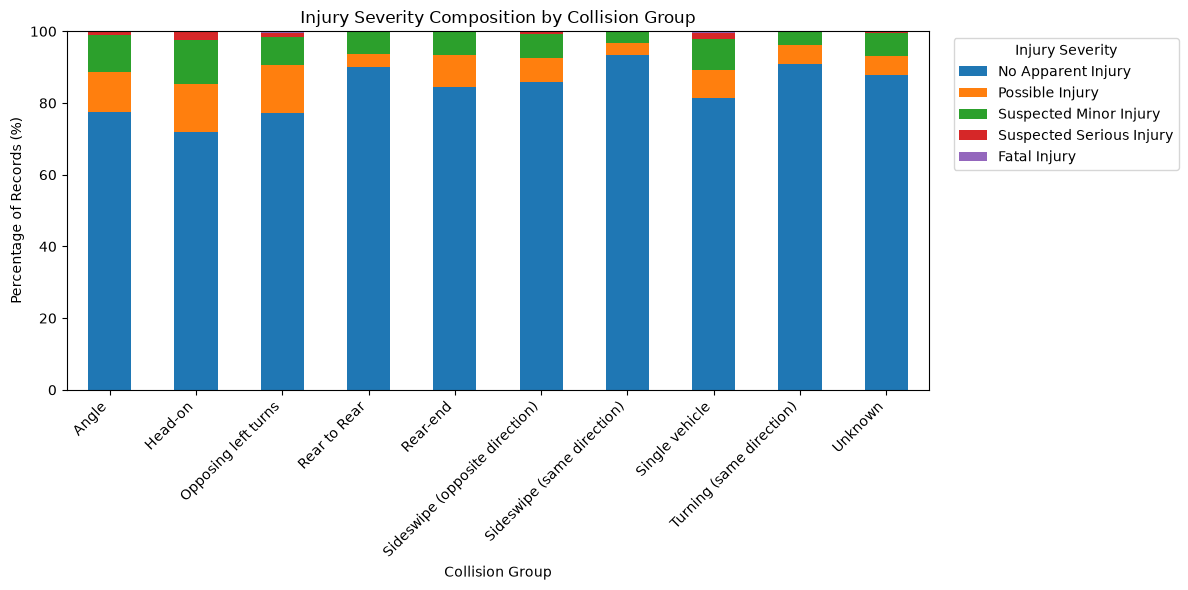

In [144]:
## Compare injury severity across collision types
severity_order = [
    "No Apparent Injury",
    "Possible Injury",
    "Suspected Minor Injury",
    "Suspected Serious Injury",
    "Fatal Injury"
]

collision_table = pd.crosstab(
    df_2022_2025["Collision Group"],
    df_2022_2025["Injury Severity"],
    normalize="index"
) * 100

collision_table = collision_table.reindex(
    columns=severity_order, fill_value=0
)

display(collision_table.round(2))

collision_table.plot(
    kind="bar", stacked=True, figsize=(12, 6)
)

plt.title("Injury Severity Composition by Collision Group")
plt.xlabel("Collision Group")
plt.ylabel("Percentage of Records (%)")
plt.xticks(rotation=45, ha="right")
plt.legend(
    title="Injury Severity",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.tight_layout()
plt.show()

# Explore weather, lighting, road surface, and traffic control
- **What to look for**: Do the severity distributions differ across weather conditions, light conditions, road surfaces, or traffic controls?

- Be cautious with rare categories. For example, a category with very few records may have a high fatal-injury percentage simply because its sample size is small.


Injury severity by Weather (%)


Injury Severity,No Apparent Injury,Possible Injury,Suspected Minor Injury,Suspected Serious Injury,Fatal Injury
Weather,,,,,
Clear,83.19,8.33,7.55,0.81,0.11
Cloudy,81.29,10.20,7.46,0.88,0.16
Fog,86.46,5.24,7.42,0.87,0.00
Rain,82.95,8.78,7.56,0.64,0.06
Sleet/Wintry Mix,85.71,5.19,7.79,1.30,0.00
Snow,82.60,9.84,7.21,0.35,0.00
Unknown,91.16,5.05,2.78,1.01,0.00
Wind,82.14,7.14,8.93,1.79,0.00


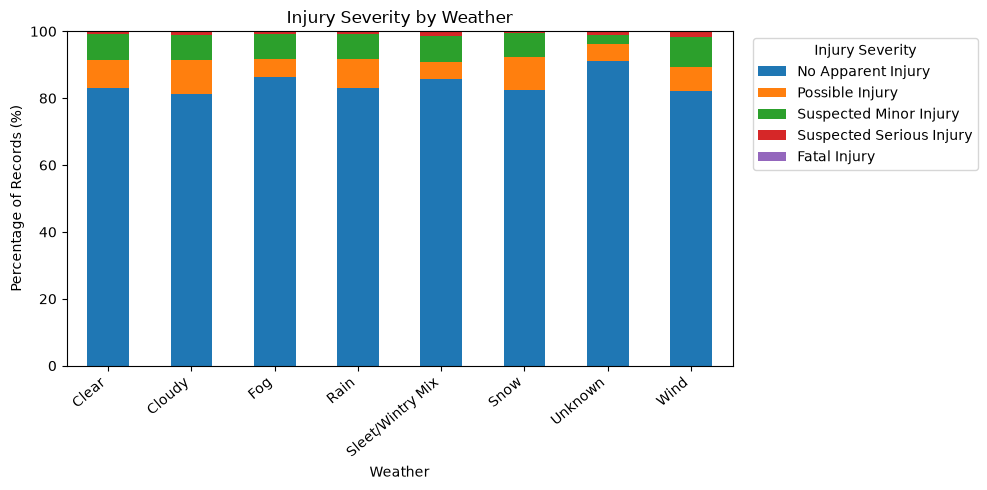


Injury severity by Light (%)


Injury Severity,No Apparent Injury,Possible Injury,Suspected Minor Injury,Suspected Serious Injury,Fatal Injury
Light,,,,,
Dark - Lighted,83.18,7.68,8.04,0.97,0.13
Dark - Not Lighted,81.06,8.97,8.38,1.28,0.32
Dark - Unknown Lighting,87.64,7.53,3.47,0.77,0.58
Dawn,79.45,10.85,8.36,0.98,0.36
Daylight,83.11,8.86,7.27,0.69,0.07
Dusk,83.91,8.09,6.47,1.28,0.26
Unknown,91.33,2.55,5.87,0.26,0.00


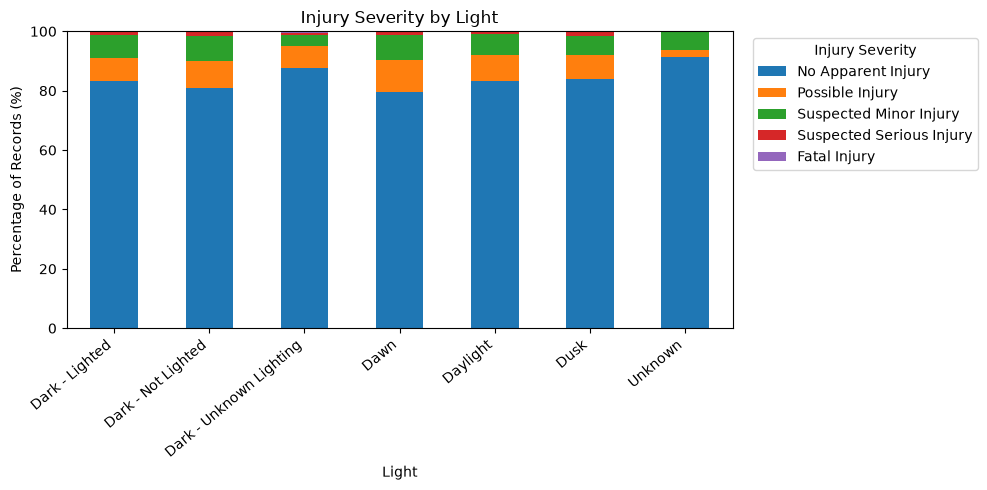


Injury severity by Surface Condition (%)


Injury Severity,No Apparent Injury,Possible Injury,Suspected Minor Injury,Suspected Serious Injury,Fatal Injury
Surface Condition,,,,,
Dry,82.03,9.00,7.98,0.86,0.13
Ice,80.91,11.97,6.47,0.32,0.32
Mud/Dirt/Gravel,76.92,7.69,15.38,0.00,0.00
Oil,66.67,16.67,16.67,0.00,0.00
Sand,100.00,0.00,0.00,0.00,0.00
Slush,76.84,12.63,10.53,0.00,0.00
Snow,84.19,9.35,5.48,0.97,0.00
Unknown,91.01,3.93,4.49,0.56,0.00
Wet,81.95,9.24,7.93,0.79,0.08


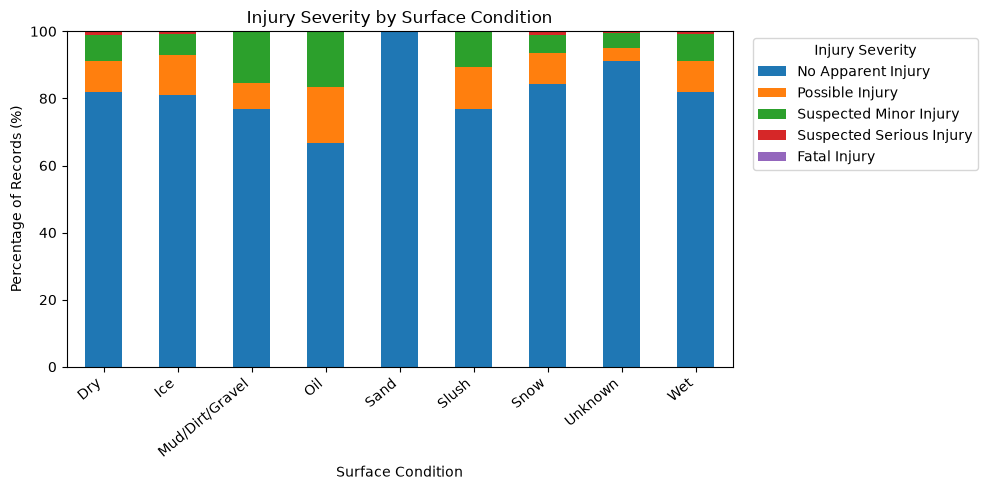


Injury severity by Traffic Control (%)


Injury Severity,No Apparent Injury,Possible Injury,Suspected Minor Injury,Suspected Serious Injury,Fatal Injury
Traffic Control,,,,,
Lane Use Control Signal,86.43,6.33,7.24,0.00,0.00
No Controls,83.99,7.75,7.18,0.96,0.12
Other,89.42,0.96,9.62,0.00,0.00
Pedestrian Crossing,82.55,7.79,9.35,0.00,0.31
Person,91.00,3.00,6.00,0.00,0.00
Stop Sign,82.14,9.83,7.32,0.61,0.10
Traffic Control Signal,80.18,10.14,8.85,0.75,0.08
Unknown,88.72,6.96,3.40,0.77,0.15
Warning Sign,86.05,3.88,9.30,0.78,0.00


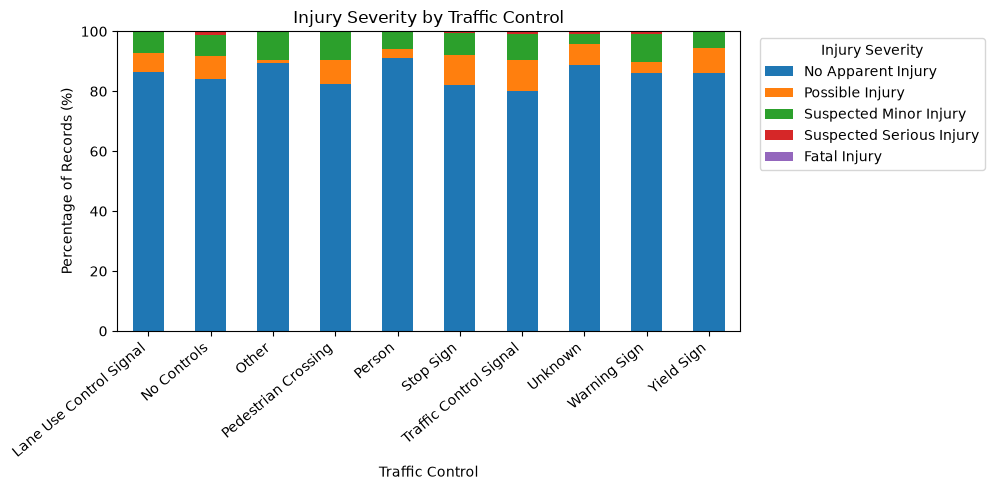

In [145]:
environment_features = [
    "Weather",
    "Light",
    "Surface Condition",
    "Traffic Control"
]

for feature in environment_features:
    if feature not in df_2022_2025.columns:
        print(f"Skipping {feature}: column not found.")
        continue

    # Show the 10 most frequent categories
    top_categories = (
        df_2022_2025[feature]
        .value_counts()
        .head(10)
        .index
    )

    subset = df_2022_2025[
        df_2022_2025[feature].isin(top_categories)
    ]

    table = pd.crosstab(
        subset[feature],
        subset["Injury Severity"],
        normalize="index"
    ) * 100

    table = table.reindex(
        columns=severity_order, fill_value=0
    )

    print(f"\nInjury severity by {feature} (%)")
    display(table.round(2))

    table.plot(
        kind="bar", stacked=True, figsize=(10, 5)
    )
    plt.title(f"Injury Severity by {feature}")
    plt.xlabel(feature)
    plt.ylabel("Percentage of Records (%)")
    plt.xticks(rotation=40, ha="right")
    plt.legend(
        title="Injury Severity",
        bbox_to_anchor=(1.02, 1),
        loc="upper left"
    )
    plt.tight_layout()
    plt.show()

# Examine numerical features (speed limit and vehicle year)
- **What to look for**: Are speed limits higher in certain severity groups? Do vehicle years differ substantially?

- Remember that Vehicle Year describes the vehicle's model year, not the crash year. Also, a boxplot shows distributions, not proof that a characteristic caused an injury.

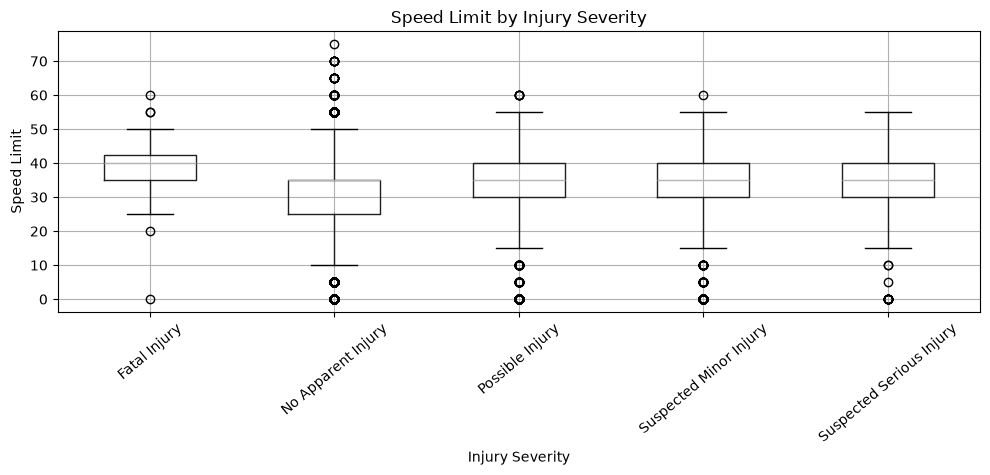


Summary statistics for Speed Limit:


,count,mean,std,min,25%,50%,75%,max
Injury Severity,,,,,,,,
Fatal Injury,75.0,37.93,8.89,0.0,35.0,40.0,42.5,60.0
No Apparent Injury,58663.0,30.73,11.81,0.0,25.0,35.0,35.0,75.0
Possible Injury,6032.0,34.16,9.38,0.0,30.0,35.0,40.0,60.0
Suspected Minor Injury,5257.0,34.15,9.28,0.0,30.0,35.0,40.0,60.0
Suspected Serious Injury,557.0,34.67,9.42,0.0,30.0,35.0,40.0,55.0


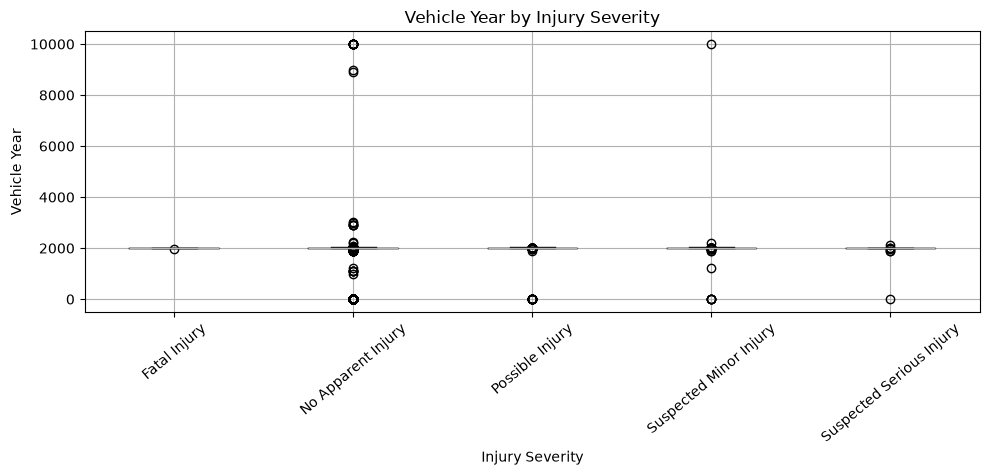


Summary statistics for Vehicle Year:


,count,mean,std,min,25%,50%,75%,max
Injury Severity,,,,,,,,
Fatal Injury,75.0,2012.39,7.64,1977.0,2007.0,2013.0,2018.0,2024.0
No Apparent Injury,58663.0,1974.38,313.12,0.0,2010.0,2016.0,2019.0,9999.0
Possible Injury,6032.0,2007.13,121.61,0.0,2011.0,2015.0,2019.0,2026.0
Suspected Minor Injury,5257.0,2014.12,127.12,0.0,2011.0,2016.0,2019.0,9999.0
Suspected Serious Injury,557.0,2009.26,85.97,0.0,2008.0,2014.0,2019.0,2109.0


In [146]:
numeric_features = ["Speed Limit", "Vehicle Year"]

for feature in numeric_features:
    if feature not in df_2022_2025.columns:
        print(f"Skipping {feature}: column not found.")
        continue

    df_2022_2025.boxplot(
        column=feature,
        by="Injury Severity",
        figsize=(10, 5),
        rot=40
    )

    plt.title(f"{feature} by Injury Severity")
    plt.suptitle("")
    plt.xlabel("Injury Severity")
    plt.ylabel(feature)
    plt.tight_layout()
    plt.show()

    print(f"\nSummary statistics for {feature}:")
    display(
        df_2022_2025.groupby("Injury Severity")[feature]
        .describe()
        .round(2)
    )

# Explore Crash timing ( Using Crash Hour, Crash Day of Week, and Crash Month)
- **What to look for**: Do the proportions of serious injuries differ by hour or weekday? Are there noticeable patterns during nighttime or weekends?

- These are descriptive patterns in reported crashes. They do not tell you the risk per trip or per mile, because the amount of traffic at each time is not accounted for.

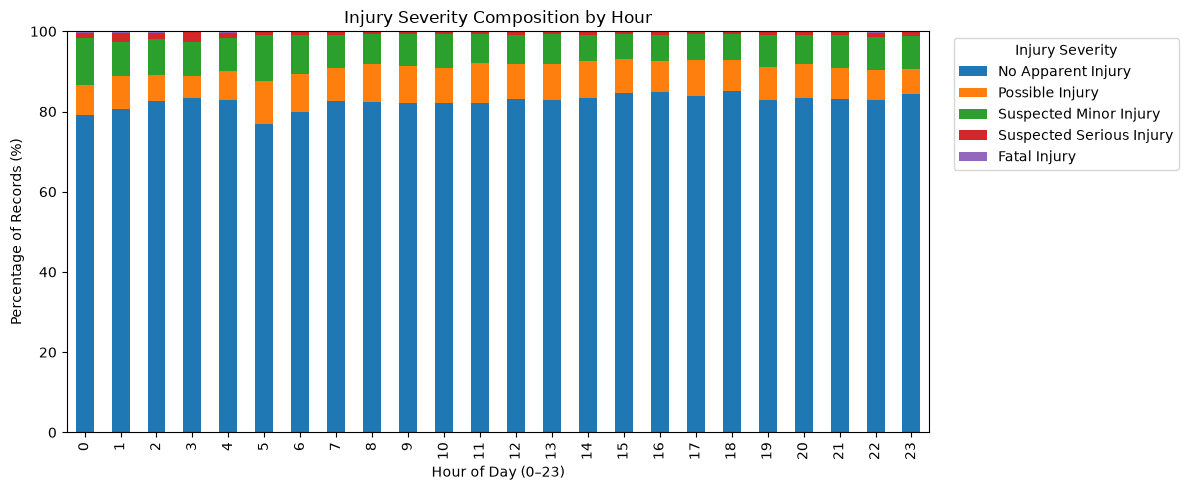

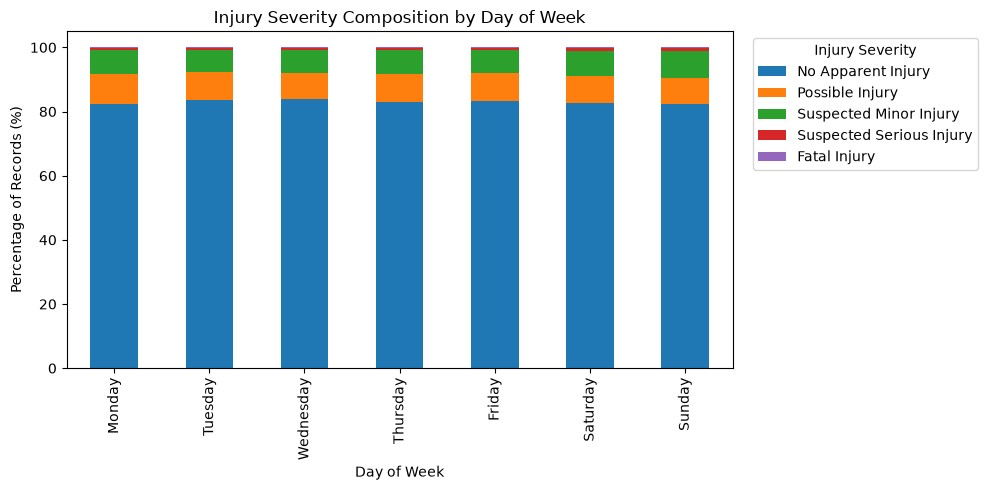

In [147]:
# Translate weekday numbers into readable names
day_names = {
    0: "Monday",
    1: "Tuesday",
    2: "Wednesday",
    3: "Thursday",
    4: "Friday",
    5: "Saturday",
    6: "Sunday"
}

# Injury severity composition by hour
hour_table = pd.crosstab(
    df_2022_2025["Crash Hour"],
    df_2022_2025["Injury Severity"],
    normalize="index"
) * 100

hour_table = hour_table.reindex(
    columns=severity_order, fill_value=0
)

hour_table.plot(
    kind="bar", stacked=True, figsize=(12, 5)
)

plt.title("Injury Severity Composition by Hour")
plt.xlabel("Hour of Day (0–23)")
plt.ylabel("Percentage of Records (%)")
plt.legend(
    title="Injury Severity",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.tight_layout()
plt.show()

# Injury severity composition by weekday
weekday_data = df_2022_2025.copy()
weekday_data["Day Name"] = (
    weekday_data["Crash Day of Week"].map(day_names)
)

weekday_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

weekday_table = pd.crosstab(
    weekday_data["Day Name"],
    weekday_data["Injury Severity"],
    normalize="index"
) * 100

weekday_table = weekday_table.reindex(
    index=weekday_order,
    columns=severity_order,
    fill_value=0
)

weekday_table.plot(
    kind="bar", stacked=True, figsize=(10, 5)
)

plt.title("Injury Severity Composition by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Percentage of Records (%)")
plt.legend(
    title="Injury Severity",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.tight_layout()
plt.show()

# Heatmap using numerical features

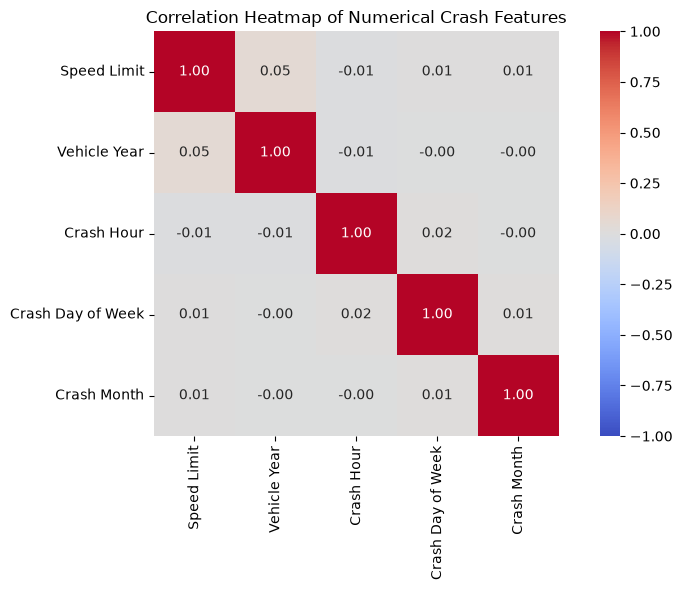

In [148]:
# Select numerical features relevant to crash characteristics
numeric_features = [
    "Speed Limit",
    "Vehicle Year",
    "Crash Hour",
    "Crash Day of Week",
    "Crash Month"
]

# Keep only columns that exist in the dataset
numeric_features = [
    col for col in numeric_features
    if col in df_2022_2025.columns
]

# Calculate correlations
corr_matrix = df_2022_2025[numeric_features].corr()

# Plot heatmap
plt.figure(figsize=(9, 6))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    fmt=".2f",
    square=True
)

plt.title("Correlation Heatmap of Numerical Crash Features")
plt.tight_layout()
plt.show()

# Heatmap Injury severity by feature

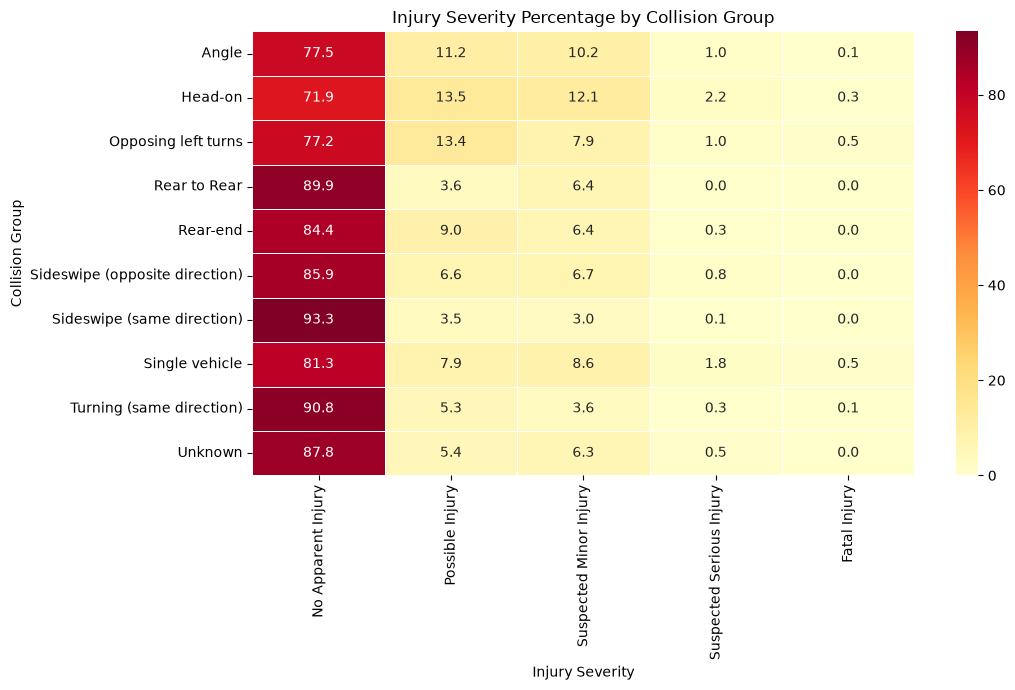

In [149]:
severity_order = [
    "No Apparent Injury",
    "Possible Injury",
    "Suspected Minor Injury",
    "Suspected Serious Injury",
    "Fatal Injury"
]

severity_heatmap = pd.crosstab(
    df_2022_2025["Collision Group"],
    df_2022_2025["Injury Severity"],
    normalize="index"
) * 100

severity_heatmap = severity_heatmap.reindex(
    columns=severity_order, fill_value=0
)

plt.figure(figsize=(11, 7))

sns.heatmap(
    severity_heatmap,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    linewidths=0.5
)

plt.title("Injury Severity Percentage by Collision Group")
plt.xlabel("Injury Severity")
plt.ylabel("Collision Group")
plt.tight_layout()
plt.show()


# Defining Target and predictors

In [150]:
# Define the target
target = "Injury Severity"

# Start with crash characteristics that could be useful
candidate_features = [
    "Collision Group",
    "Weather",
    "Surface Condition",
    "Light",
    "Traffic Control",
    "Speed Limit",
    "Vehicle Body Type",
    "Vehicle Movement",
    "Vehicle Going Dir",
    "Route Type",
    "Municipality",
    "Crash Hour",
    "Crash Day of Week",
    "Crash Month"
]

# Keep only columns that exist
features = [
    col for col in candidate_features
    if col in df_2022_2025.columns
]

# Create the modeling dataset
df_model = df_2022_2025[features + [target]].copy()

X = df_model[features]

X = df_model[features].copy()

# Convert pandas string columns to standard object columns
# and represent missing values as np.nan
for col in X.select_dtypes(
    include=["object", "category", "string"]
).columns:
    X[col] = X[col].astype(object)
    X[col] = X[col].where(X[col].notna(), np.nan)

y = df_model[target]

y = df_model[target]

print("Number of records:", len(df_model))
print("Number of predictors:", len(features))
print("Predictors:", features)
print("\nTarget distribution:")
display(y.value_counts().to_frame("Count"))


Number of records: 73077
Number of predictors: 13
Predictors: ['Collision Group', 'Weather', 'Surface Condition', 'Light', 'Traffic Control', 'Speed Limit', 'Vehicle Body Type', 'Vehicle Movement', 'Vehicle Going Dir', 'Route Type', 'Crash Hour', 'Crash Day of Week', 'Crash Month']

Target distribution:


,Count
Injury Severity,
No Apparent Injury,58663
Possible Injury,6032
Suspected Minor Injury,5257
Suspected Serious Injury,557
Fatal Injury,75


# **EDA Imputation**

Prepare the modeling dataset

In [151]:
# Define target variable
target = "Injury Severity"

# Select candidate predictor features
candidate_features = [
    "Collision Group",
    "Weather",
    "Surface Condition",
    "Light",
    "Traffic Control",
    "Speed Limit",
    "Vehicle Body Type",
    "Vehicle Movement",
    "Vehicle Going Dir",
    "Route Type",
    "Crash Hour",
    "Crash Day of Week",
    "Crash Month"
]

# Keep only features that exist in the dataset
features = [
    col for col in candidate_features
    if col in df_2022_2025.columns
]

# Create a separate modeling dataset
# Remove rows with missing target values only
df_model = df_2022_2025.loc[
    df_2022_2025[target].notna()
].copy()

# Standardize target text
df_model[target] = df_model[target].astype(str).str.strip()

# Keep only valid injury severity categories
valid_severity = [
    "No Apparent Injury",
    "Possible Injury",
    "Suspected Minor Injury",
    "Suspected Serious Injury",
    "Fatal Injury"
]

df_model = df_model.loc[
    df_model[target].isin(valid_severity)
].copy()

# Create predictor matrix and target vector
X = df_model[features].copy()
y = df_model[target].copy()

# Display dataset information
print("Original cleaned dataset:", df_2022_2025.shape)
print("Modeling dataset:", df_model.shape)
print("Number of predictor features:", len(features))

print("\nSelected features:")
print(features)

print("\nInjury Severity counts:")
print(y.value_counts())

print("\nInjury Severity percentages:")
print((y.value_counts(normalize=True) * 100).round(2))


Original cleaned dataset: (73077, 43)
Modeling dataset: (70584, 43)
Number of predictor features: 13

Selected features:
['Collision Group', 'Weather', 'Surface Condition', 'Light', 'Traffic Control', 'Speed Limit', 'Vehicle Body Type', 'Vehicle Movement', 'Vehicle Going Dir', 'Route Type', 'Crash Hour', 'Crash Day of Week', 'Crash Month']

Injury Severity counts:
Injury Severity
No Apparent Injury          58663
Possible Injury              6032
Suspected Minor Injury       5257
Suspected Serious Injury      557
Fatal Injury                   75
Name: count, dtype: int64

Injury Severity percentages:
Injury Severity
No Apparent Injury          83.11
Possible Injury              8.55
Suspected Minor Injury       7.45
Suspected Serious Injury     0.79
Fatal Injury                 0.11
Name: proportion, dtype: float64


Rows before target filtering: 73077
Rows after target filtering: 70584
Rows removed: 2493


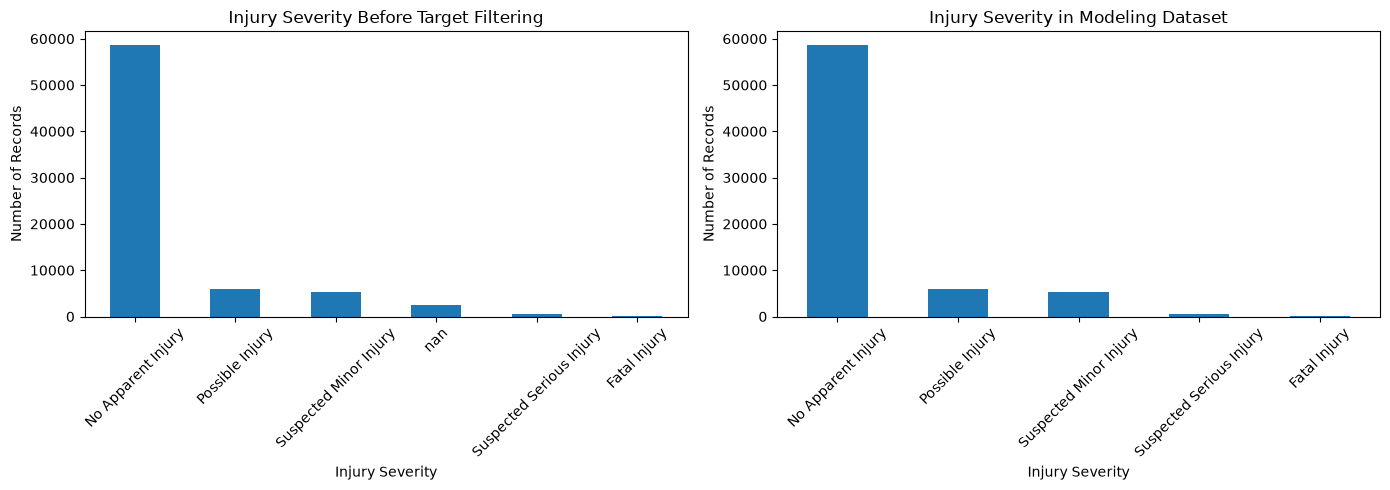


Missing predictor values in df_model:
Traffic Control      7200
Surface Condition    7050
Vehicle Going Dir    6718
Route Type           6516
Weather              2701
Vehicle Movement      908
Vehicle Body Type     666
Light                 291
Collision Group       132
Speed Limit             0
Crash Hour              0
Crash Day of Week       0
Crash Month             0
dtype: int64


In [152]:
# Compare dataset sizes
print("Rows before target filtering:", len(df_2022_2025))
print("Rows after target filtering:", len(df_model))
print("Rows removed:", len(df_2022_2025) - len(df_model))

# Compare injury severity distributions
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

df_2022_2025[target].value_counts(dropna=False).plot(
    kind="bar", ax=axes[0]
)
axes[0].set_title("Injury Severity Before Target Filtering")
axes[0].set_xlabel("Injury Severity")
axes[0].set_ylabel("Number of Records")
axes[0].tick_params(axis="x", rotation=45)

df_model[target].value_counts().plot(
    kind="bar", ax=axes[1]
)
axes[1].set_title("Injury Severity in Modeling Dataset")
axes[1].set_xlabel("Injury Severity")
axes[1].set_ylabel("Number of Records")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

# Check missing predictor values
print("\nMissing predictor values in df_model:")
print(
    df_model[features]
    .isna()
    .sum()
    .sort_values(ascending=False)
)


Split training and testing data
- New split is now (2022-2024) train/(2025) test

In [153]:
# Split by crash year
train_df = df_model[
    df_model["Crash Year"].between(2022, 2024)
].copy()

test_df = df_model[
    df_model["Crash Year"] == 2025
].copy()

# Create training and testing predictors
X_train = train_df[features].copy()
X_test = test_df[features].copy()

# Create training and testing targets
y_train = train_df[target].copy()
y_test = test_df[target].copy()

# Check split sizes
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining severity distribution:")
print(y_train.value_counts())

print("\nTesting severity distribution:")
print(y_test.value_counts())

# Check for empty splits
assert len(X_train) > 0, "Training dataset is empty."
assert len(X_test) > 0, "Testing dataset is empty."


Training records: 53968
Testing records: 16616

Training severity distribution:
Injury Severity
No Apparent Injury          44904
Possible Injury              4789
Suspected Minor Injury       3795
Suspected Serious Injury      424
Fatal Injury                   56
Name: count, dtype: int64

Testing severity distribution:
Injury Severity
No Apparent Injury          13759
Suspected Minor Injury       1462
Possible Injury              1243
Suspected Serious Injury      133
Fatal Injury                   19
Name: count, dtype: int64


Separate numeric and categorical features

In [154]:
# Identify numeric features
numeric_features = [
    col for col in [
        "Speed Limit",
        "Crash Hour",
        "Crash Day of Week",
        "Crash Month"
    ]
    if col in features
]

# All remaining features are categorical
categorical_features = [
    col for col in features
    if col not in numeric_features
]

# Convert numeric columns safely
for col in numeric_features:
    X_train[col] = pd.to_numeric(
        X_train[col], errors="coerce"
    )
    X_test[col] = pd.to_numeric(
        X_test[col], errors="coerce"
    )

# Ensure categorical values are handled consistently
for col in categorical_features:
    X_train[col] = X_train[col].astype("object")
    X_test[col] = X_test[col].astype("object")

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)


Numeric features: ['Speed Limit', 'Crash Hour', 'Crash Day of Week', 'Crash Month']
Categorical features: ['Collision Group', 'Weather', 'Surface Condition', 'Light', 'Traffic Control', 'Vehicle Body Type', 'Vehicle Movement', 'Vehicle Going Dir', 'Route Type']


Imputation and preprocessing pipeline

In [155]:

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Numeric preprocessing:
# 1. Fill missing values with the median
# 2. Standardize numeric features
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing:
# 1. Fill missing values with the most frequent category
# 2. Convert categories into numerical indicator columns
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=10
    ))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

print("Imputation and preprocessing pipeline created.")


Imputation and preprocessing pipeline created.


Fit the baseline model and generate predictions
- baseline is logistic regression

In [156]:

from sklearn.linear_model import LogisticRegression

# Create the complete modeling pipeline
baseline_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ))
])

# Fit model:
# Imputation and preprocessing are learned from training data only
baseline_model.fit(X_train, y_train)

# Generate predictions for 2025
y_pred = baseline_model.predict(X_test)

print("Model fitted successfully.")
print("Predictions generated:", len(y_pred))


d:\schoolcoding\CodingStuff\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


Model fitted successfully.
Predictions generated: 16616


Accuracy: 0.407
Balanced Accuracy: 0.3529
Macro F1 Score: 0.1965

Classification Report:
                          precision    recall  f1-score   support

      No Apparent Injury       0.91      0.43      0.58     13759
         Possible Injury       0.10      0.32      0.16      1243
  Suspected Minor Injury       0.13      0.31      0.18      1462
Suspected Serious Injury       0.03      0.40      0.05       133
            Fatal Injury       0.01      0.32      0.01        19

                accuracy                           0.41     16616
               macro avg       0.24      0.35      0.20     16616
            weighted avg       0.78      0.41      0.51     16616



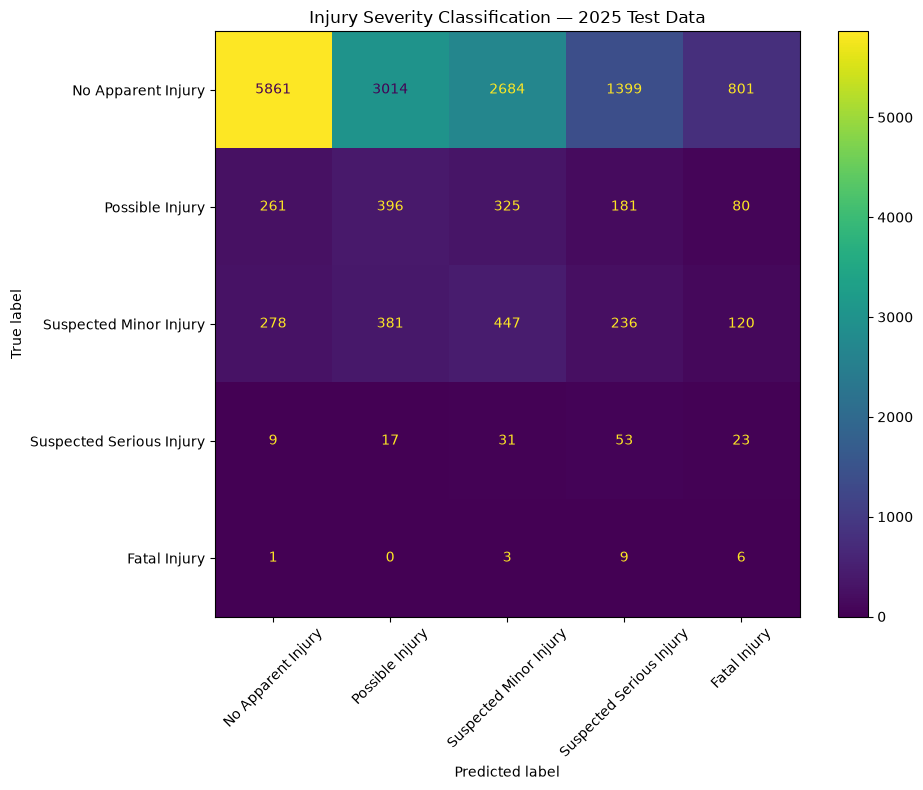

In [157]:

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    ConfusionMatrixDisplay
)

# Calculate performance metrics
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print(
    "Balanced Accuracy:",
    round(balanced_accuracy_score(y_test, y_pred), 4)
)
print(
    "Macro F1 Score:",
    round(f1_score(
        y_test, y_pred,
        average="macro",
        zero_division=0
    ), 4)
)

# Detailed classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=valid_severity,
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=valid_severity
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=valid_severity
)

fig, ax = plt.subplots(figsize=(10, 8))
disp.plot(
    ax=ax,
    xticks_rotation=45,
    values_format="d"
)
plt.title("Injury Severity Classification — 2025 Test Data")
plt.tight_layout()
plt.show()


In [158]:

# Transform a sample using the fitted preprocessing pipeline
sample_size = min(1000, len(X_test))

X_test_sample = X_test.iloc[:sample_size]

X_test_transformed = baseline_model.named_steps[
    "preprocessor"
].transform(X_test_sample)

# Check for missing values in the transformed data
if hasattr(X_test_transformed, "toarray"):
    transformed_sample = X_test_transformed.toarray()
else:
    transformed_sample = X_test_transformed

print(
    "Missing values after preprocessing:",
    np.isnan(transformed_sample).sum()
)


Missing values after preprocessing: 0


# **Notes: After EDA Imputation**
- Target variable class imbalance is still an issue
- Logistic Regression performed with 37.72% accuracy, 32.46% recall, 17.44% Macro F1. 0 missing values due to imputation. (Overall Poor)

> **Update (Oct 23):** The numbers in these notes are from before the 2024 label fix in the cleaning section. Rerun the notebook and check the outputs above for current values.

# **Target Variable Class Imbalance Treatment**

In [159]:
%pip install -q imbalanced-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [160]:

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler

# Baseline: class weighting, without resampling.
baseline_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ))
])

# Method 1: random oversampling.
random_over_pipeline = ImbPipeline(steps=[
    ("preprocessor", preprocessor),
    ("resampler", RandomOverSampler(
        sampling_strategy="not majority",
        random_state=42
    )),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

# Method 2: random undersampling.
# Keep 10,000 observations in the majority class.
undersample_pipeline = ImbPipeline(steps=[
    ("preprocessor", preprocessor),
    ("resampler", RandomUnderSampler(
        sampling_strategy={
            "No Apparent Injury": 10000
        },
        random_state=42
    )),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

print("Baseline and resampling pipelines defined.")


Baseline and resampling pipelines defined.


Create a 2022–2024 modeling dataset
- df_development is a copy of the 2022-2024 split data (still trying to figure out the imbalance stuff with this rather than directly working on Kelly's df_2022_2025)

In [161]:

# Keep only 2022–2024 data for model development.
# Do not use the previous 2025 test set.

target = "Injury Severity"

valid_severity = [
    "No Apparent Injury",
    "Possible Injury",
    "Suspected Minor Injury",
    "Suspected Serious Injury",
    "Fatal Injury"
]

features = [
    "Collision Group",
    "Weather",
    "Surface Condition",
    "Light",
    "Traffic Control",
    "Speed Limit",
    "Vehicle Body Type",
    "Vehicle Movement",
    "Vehicle Going Dir",
    "Route Type",
    "Crash Hour",
    "Crash Day of Week",
    "Crash Month"
]

df_development = df_2022_2025[
    df_2022_2025["Crash Year"].isin([2022, 2023, 2024])
].copy()

df_development = df_development[
    df_development[target].isin(valid_severity)
].copy()

print("Development dataset shape:", df_development.shape)

print("\nRecords by year:")
print(df_development["Crash Year"].value_counts().sort_index())

print("\nInjury severity distribution:")
print(df_development[target].value_counts())

print("\nClass proportions:")
print(
    (df_development[target].value_counts(normalize=True) * 100)
    .round(2)
)


Development dataset shape: (53968, 43)

Records by year:
Crash Year
2022    17582
2023    18928
2024    17458
Name: count, dtype: int64

Injury severity distribution:
Injury Severity
No Apparent Injury          44904
Possible Injury              4789
Suspected Minor Injury       3795
Suspected Serious Injury      424
Fatal Injury                   56
Name: count, dtype: int64

Class proportions:
Injury Severity
No Apparent Injury          83.20
Possible Injury              8.87
Suspected Minor Injury       7.03
Suspected Serious Injury     0.79
Fatal Injury                 0.10
Name: proportion, dtype: float64


Make a chronological training/validation split

Note:
- even though we are splitting again, this is NOT a stratified random split

In [162]:

# Train on 2022–2023 and validate on 2024.

train_data = df_development[
    df_development["Crash Year"].isin([2022, 2023])
].copy()

val_data = df_development[
    df_development["Crash Year"] == 2024
].copy()

X_train = train_data[features]
y_train = train_data[target]

X_val = val_data[features]
y_val = val_data[target]

print("Training records:", len(X_train))
print("Validation records:", len(X_val))

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nValidation class distribution:")
print(y_val.value_counts())


Training records: 36510
Validation records: 17458

Training class distribution:
Injury Severity
No Apparent Injury          30473
Possible Injury              3552
Suspected Minor Injury       2179
Suspected Serious Injury      268
Fatal Injury                   38
Name: count, dtype: int64

Validation class distribution:
Injury Severity
No Apparent Injury          14431
Suspected Minor Injury       1616
Possible Injury              1237
Suspected Serious Injury      156
Fatal Injury                   18
Name: count, dtype: int64


Define preprocessing once

In [163]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression

numeric_features = [
    "Speed Limit",
    "Crash Hour",
    "Crash Day of Week",
    "Crash Month"
]

categorical_features = [
    "Collision Group",
    "Weather",
    "Surface Condition",
    "Light",
    "Traffic Control",
    "Vehicle Body Type",
    "Vehicle Movement",
    "Vehicle Going Dir",
    "Route Type"
]

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=10
    ))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing setup complete.")


Preprocessing setup complete.


Compare imbalance methods

In [164]:

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report
)

models = {
    "Class-weighted Logistic Regression": baseline_pipeline,
    "Random Oversampling": random_over_pipeline,
    "Random Undersampling": undersample_pipeline
}

validation_results = []

for name, model in models.items():
    print(f"\n{'=' * 65}")
    print(name)
    print("=" * 65)

    model.fit(X_train, y_train)
    y_val_pred = model.predict(X_val)

    accuracy = accuracy_score(y_val, y_val_pred)
    balanced_accuracy = balanced_accuracy_score(y_val, y_val_pred)
    macro_f1 = f1_score(
        y_val,
        y_val_pred,
        labels=valid_severity,
        average="macro",
        zero_division=0
    )

    validation_results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Balanced Accuracy": balanced_accuracy,
        "Macro F1": macro_f1
    })

    print(f"Accuracy: {accuracy:.4f}")
    print(f"Balanced accuracy: {balanced_accuracy:.4f}")
    print(f"Macro F1: {macro_f1:.4f}")

    print("\nClassification report:")
    print(classification_report(
        y_val,
        y_val_pred,
        labels=valid_severity,
        zero_division=0
    ))

validation_comparison = (
    __import__("pandas")
    .DataFrame(validation_results)
    .sort_values("Macro F1", ascending=False)
)

print("\nValidation comparison:")
print(validation_comparison.to_string(index=False))



Class-weighted Logistic Regression


d:\schoolcoding\CodingStuff\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


Accuracy: 0.4288
Balanced accuracy: 0.3504
Macro F1: 0.2009

Classification report:
                          precision    recall  f1-score   support

      No Apparent Injury       0.90      0.46      0.61     14431
         Possible Injury       0.09      0.33      0.14      1237
  Suspected Minor Injury       0.14      0.25      0.18      1616
Suspected Serious Injury       0.03      0.38      0.06       156
            Fatal Injury       0.01      0.33      0.01        18

                accuracy                           0.43     17458
               macro avg       0.24      0.35      0.20     17458
            weighted avg       0.77      0.43      0.53     17458


Random Oversampling


d:\schoolcoding\CodingStuff\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


Accuracy: 0.4263
Balanced accuracy: 0.3455
Macro F1: 0.1990

Classification report:
                          precision    recall  f1-score   support

      No Apparent Injury       0.91      0.46      0.61     14431
         Possible Injury       0.09      0.31      0.14      1237
  Suspected Minor Injury       0.14      0.26      0.18      1616
Suspected Serious Injury       0.03      0.37      0.06       156
            Fatal Injury       0.01      0.33      0.01        18

                accuracy                           0.43     17458
               macro avg       0.23      0.35      0.20     17458
            weighted avg       0.77      0.43      0.53     17458


Random Undersampling


d:\schoolcoding\CodingStuff\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


Accuracy: 0.8215
Balanced accuracy: 0.2163
Macro F1: 0.2134

Classification report:
                          precision    recall  f1-score   support

      No Apparent Injury       0.83      0.99      0.90     14431
         Possible Injury       0.13      0.02      0.03      1237
  Suspected Minor Injury       0.33      0.02      0.04      1616
Suspected Serious Injury       0.31      0.05      0.09       156
            Fatal Injury       0.00      0.00      0.00        18

                accuracy                           0.82     17458
               macro avg       0.32      0.22      0.21     17458
            weighted avg       0.73      0.82      0.75     17458


Validation comparison:
                             Model  Accuracy  Balanced Accuracy  Macro F1
              Random Undersampling  0.821457           0.216330  0.213406
Class-weighted Logistic Regression  0.428801           0.350405  0.200859
               Random Oversampling  0.426337           0.345517  0.199023

**Check this gpt interpretation**

The class-weighted logistic regression is currently the best of these three on both balanced accuracy and macro F1. However, those scores remain low.
- Class-weighted logistic regression: identifies some possible and suspected serious injuries, but misses all fatal injuries and nearly all suspected minor injuries.
- Random oversampling: increases recall for possible injuries from 0.16 to 0.28, but does not improve the overall macro F1.
- Random undersampling: achieves the highest accuracy by predicting almost everything as “No Apparent Injury.” It fails to identify any of the four minority classes, so this is not a useful result for our research goal.
The key lesson is that high accuracy does not mean the model can distinguish injury severity well.

> **Update (Oct 23):** The notes above describe the *first* run of this notebook, before two problems were found:
> 1. Montgomery County changed several category labels starting in 2024 (e.g. `PASSENGER CAR` became `Passenger Car`, `North` became `Northbound`). Models trained on 2022-2023 treated 4 of the 13 features as unknown on 2024 data. This is why SMOTENC predicted only "No Apparent Injury". It is now fixed in the cleaning section.
> 2. Random undersampling only cut "No Apparent Injury" to 10,000 rows, so the data stayed imbalanced.
>
> After rerunning, the outputs in this section will differ from the text above. See **Class Balancing Revisited** near the end for the corrected comparison.

# **SMOTENC and SMOTE Consideration?**

Experiment A — Test SMOTENC on the original five-class target

In [165]:

from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report
)
from sklearn.linear_model import LogisticRegression
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTENC

# First stage: impute missing values and encode categories for SMOTENC.
smotenc_preprocessor = ColumnTransformer(
    transformers=[
        ("num", SimpleImputer(strategy="median"), numeric_features),
        ("cat", Pipeline(steps=[
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("ordinal", OrdinalEncoder(
                handle_unknown="use_encoded_value",
                unknown_value=-1
            ))
        ]), categorical_features)
    ],
    verbose_feature_names_out=False
)

# The numeric columns come first, followed by the categorical columns.
categorical_indices = list(
    range(len(numeric_features), len(numeric_features) + len(categorical_features))
)

# Second stage: scale numeric columns and one-hot encode categorical columns.
final_preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), list(range(len(numeric_features)))),
        ("cat", OneHotEncoder(
            handle_unknown="ignore",
            min_frequency=10
        ), categorical_indices)
    ]
)

smotenc_pipeline = ImbPipeline(steps=[
    ("preprocess_for_sampling", smotenc_preprocessor),
    ("resampler", SMOTENC(
        categorical_features=categorical_indices,
        sampling_strategy="not majority",
        random_state=42,
        k_neighbors=5
    )),
    ("preprocessor", final_preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

# Fit ONLY on 2022–2023, then evaluate on 2024.
smotenc_pipeline.fit(X_train, y_train)
y_val_smotenc = smotenc_pipeline.predict(X_val)

print("SMOTENC — five-class target")
print("Accuracy:", round(accuracy_score(y_val, y_val_smotenc), 4))
print("Balanced accuracy:", round(
    balanced_accuracy_score(y_val, y_val_smotenc), 4
))
print("Macro F1:", round(
    f1_score(
        y_val, y_val_smotenc,
        labels=valid_severity,
        average="macro",
        zero_division=0
    ), 4
))

print("\nClassification report:")
print(classification_report(
    y_val,
    y_val_smotenc,
    labels=valid_severity,
    zero_division=0
))


d:\schoolcoding\CodingStuff\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


SMOTENC — five-class target
Accuracy: 0.5516
Balanced accuracy: 0.3271
Macro F1: 0.221

Classification report:
                          precision    recall  f1-score   support

      No Apparent Injury       0.87      0.62      0.73     14431
         Possible Injury       0.09      0.20      0.12      1237
  Suspected Minor Injury       0.13      0.21      0.16      1616
Suspected Serious Injury       0.04      0.32      0.07       156
            Fatal Injury       0.01      0.28      0.02        18

                accuracy                           0.55     17458
               macro avg       0.23      0.33      0.22     17458
            weighted avg       0.74      0.55      0.62     17458



Experiment A2 — Consider standard SMOTE as a comparison

In [166]:

from imblearn.over_sampling import SMOTE
from sklearn.base import clone

smote_pipeline = ImbPipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("resampler", SMOTE(
        sampling_strategy="not majority",
        random_state=42,
        k_neighbors=5
    )),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

# Training data only is resampled.
smote_pipeline.fit(X_train, y_train)
y_val_smote = smote_pipeline.predict(X_val)

print("Standard SMOTE — five-class target")
print("Accuracy:", round(accuracy_score(y_val, y_val_smote), 4))
print("Balanced accuracy:", round(
    balanced_accuracy_score(y_val, y_val_smote), 4
))
print("Macro F1:", round(
    f1_score(
        y_val, y_val_smote,
        labels=valid_severity,
        average="macro",
        zero_division=0
    ), 4
))

print("\nClassification report:")
print(classification_report(
    y_val,
    y_val_smote,
    labels=valid_severity,
    zero_division=0
))


d:\schoolcoding\CodingStuff\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


Standard SMOTE — five-class target
Accuracy: 0.453
Balanced accuracy: 0.3546
Macro F1: 0.204

Classification report:
                          precision    recall  f1-score   support

      No Apparent Injury       0.90      0.49      0.64     14431
         Possible Injury       0.09      0.29      0.14      1237
  Suspected Minor Injury       0.14      0.24      0.18      1616
Suspected Serious Injury       0.03      0.37      0.06       156
            Fatal Injury       0.01      0.39      0.01        18

                accuracy                           0.45     17458
               macro avg       0.23      0.35      0.20     17458
            weighted avg       0.76      0.45      0.55     17458



Experiment B — Merge suspected serious and fatal injuries

In [167]:

# Create a separate four-class target.
# Do not overwrite the original five-class target.

severe_fatal_label = "Severe/Fatal Injury"

y_train_4 = y_train.replace({
    "Suspected Serious Injury": severe_fatal_label,
    "Fatal Injury": severe_fatal_label
})

y_val_4 = y_val.replace({
    "Suspected Serious Injury": severe_fatal_label,
    "Fatal Injury": severe_fatal_label
})

severity_4 = [
    "No Apparent Injury",
    "Possible Injury",
    "Suspected Minor Injury",
    severe_fatal_label
]

print("Four-class training distribution:")
print(y_train_4.value_counts())

print("\nFour-class validation distribution:")
print(y_val_4.value_counts())


Four-class training distribution:
Injury Severity
No Apparent Injury        30473
Possible Injury            3552
Suspected Minor Injury     2179
Severe/Fatal Injury         306
Name: count, dtype: int64

Four-class validation distribution:
Injury Severity
No Apparent Injury        14431
Suspected Minor Injury     1616
Possible Injury            1237
Severe/Fatal Injury         174
Name: count, dtype: int64


Now compare class weighting, SMOTENC, and standard SMOTE on this four-class target.

In [168]:

# Four-class baseline.
baseline_4 = clone(baseline_pipeline)
baseline_4.fit(X_train, y_train_4)
pred_baseline_4 = baseline_4.predict(X_val)

# Four-class SMOTENC.
smotenc_4 = clone(smotenc_pipeline)
smotenc_4.fit(X_train, y_train_4)
pred_smotenc_4 = smotenc_4.predict(X_val)

# Four-class standard SMOTE.
smote_4 = clone(smote_pipeline)
smote_4.fit(X_train, y_train_4)
pred_smote_4 = smote_4.predict(X_val)

four_class_models = {
    "Class-weighted Logistic Regression": pred_baseline_4,
    "SMOTENC": pred_smotenc_4,
    "Standard SMOTE": pred_smote_4
}

four_class_results = []

for name, predictions in four_class_models.items():
    four_class_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val_4, predictions),
        "Balanced Accuracy": balanced_accuracy_score(y_val_4, predictions),
        "Macro F1": f1_score(
            y_val_4,
            predictions,
            labels=severity_4,
            average="macro",
            zero_division=0
        )
    })

    print(f"\n{'=' * 60}")
    print(name)
    print("=" * 60)
    print(classification_report(
        y_val_4,
        predictions,
        labels=severity_4,
        zero_division=0
    ))

four_class_comparison = (
    __import__("pandas")
    .DataFrame(four_class_results)
    .sort_values("Macro F1", ascending=False)
)

print("\nFour-class validation comparison:")
print(four_class_comparison.to_string(index=False))


d:\schoolcoding\CodingStuff\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
d:\schoolcoding\CodingStuff\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
d:\schoolcoding\CodingStuff\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(



Class-weighted Logistic Regression
                        precision    recall  f1-score   support

    No Apparent Injury       0.90      0.46      0.61     14431
       Possible Injury       0.09      0.35      0.15      1237
Suspected Minor Injury       0.14      0.27      0.18      1616
   Severe/Fatal Injury       0.04      0.55      0.08       174

              accuracy                           0.44     17458
             macro avg       0.29      0.41      0.25     17458
          weighted avg       0.77      0.44      0.54     17458


SMOTENC
                        precision    recall  f1-score   support

    No Apparent Injury       0.87      0.62      0.73     14431
       Possible Injury       0.09      0.21      0.13      1237
Suspected Minor Injury       0.14      0.22      0.17      1616
   Severe/Fatal Injury       0.05      0.41      0.08       174

              accuracy                           0.56     17458
             macro avg       0.29      0.37      0.28 

# **Tree-Based Models (Four-Class Target)**
- Same setup as Experiment B: train on 2022-2023, validate on 2024, with Suspected Serious and Fatal merged into "Severe/Fatal Injury".
- Trees do not need scaling or one-hot encoding, so each categorical feature is ordinal-encoded into a single integer column.
- Imbalance is handled with class weights, not resampling, because class weighting beat SMOTE/SMOTENC for logistic regression.
- Goal: beat the class-weighted logistic regression from Experiment B.

Shared tree preprocessing and helper functions

In [169]:
import pandas as pd
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report
)

# Trees split on thresholds, so scaling and one-hot encoding are not needed.
# Each category becomes one integer column instead.
# Categories with fewer than 10 rows are grouped; unseen categories become -1.
tree_preprocessor = ColumnTransformer(
    transformers=[
        ("num", SimpleImputer(strategy="median"), numeric_features),
        ("cat", Pipeline(steps=[
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("ordinal", OrdinalEncoder(
                handle_unknown="use_encoded_value",
                unknown_value=-1,
                min_frequency=10
            ))
        ]), categorical_features)
    ],
    verbose_feature_names_out=False
)

# Numeric columns come first, then categorical columns.
categorical_mask = (
    [False] * len(numeric_features)
    + [True] * len(categorical_features)
)

# XGBoost needs integer class labels.
label_to_code = {label: code for code, label in enumerate(severity_4)}
code_to_label = {code: label for label, code in label_to_code.items()}

# Unfitted tree pipelines are added here by the cells below.
tree_pipelines = {}
tree_results = []


def fit_four_class(name, X, y):
    """Fit a fresh copy of a tree pipeline on a four-class target."""
    model = clone(tree_pipelines[name])

    if name == "XGBoost":
        # XGBoost has no class_weight option, so weight each row instead.
        model.fit(
            X,
            y.map(label_to_code),
            classifier__sample_weight=compute_sample_weight("balanced", y)
        )
    else:
        model.fit(X, y)

    return model


def predict_four_class(name, model, X):
    """Return predictions as severity labels."""
    predictions = model.predict(X)

    if name == "XGBoost":
        predictions = pd.Series(predictions).map(code_to_label).to_numpy()

    return predictions


def evaluate_four_class(name, y_true, predictions):
    """Print the classification report and return the summary metrics."""
    print(f"\n{'=' * 60}")
    print(name)
    print("=" * 60)
    print(classification_report(
        y_true,
        predictions,
        labels=severity_4,
        zero_division=0
    ))

    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Balanced Accuracy": balanced_accuracy_score(y_true, predictions),
        "Macro F1": f1_score(
            y_true,
            predictions,
            labels=severity_4,
            average="macro",
            zero_division=0
        )
    }


print("Tree preprocessing and helpers defined.")

Tree preprocessing and helpers defined.


Model 1: Random Forest
- `class_weight="balanced_subsample"` reweights classes inside each tree's bootstrap sample.

In [170]:
from sklearn.ensemble import RandomForestClassifier

# balanced_subsample recomputes class weights inside each bootstrap sample.
# min_samples_leaf stops trees from memorizing single rare-class records.
tree_pipelines["Random Forest"] = Pipeline(steps=[
    ("preprocessor", tree_preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=20,
        class_weight="balanced_subsample",
        n_jobs=-1,
        random_state=42
    ))
])

rf_model = fit_four_class("Random Forest", X_train, y_train_4)
pred_rf_4 = predict_four_class("Random Forest", rf_model, X_val)

tree_results.append(
    evaluate_four_class("Random Forest", y_val_4, pred_rf_4)
)


Random Forest
                        precision    recall  f1-score   support

    No Apparent Injury       0.88      0.66      0.75     14431
       Possible Injury       0.10      0.32      0.15      1237
Suspected Minor Injury       0.15      0.20      0.17      1616
   Severe/Fatal Injury       0.11      0.30      0.16       174

              accuracy                           0.59     17458
             macro avg       0.31      0.37      0.31     17458
          weighted avg       0.75      0.59      0.65     17458



Model 2: Histogram Gradient Boosting
- Built into scikit-learn; uses the categorical columns directly.

In [171]:
from sklearn.ensemble import HistGradientBoostingClassifier

# Gradient boosting that handles the categorical columns natively.
tree_pipelines["Histogram Gradient Boosting"] = Pipeline(steps=[
    ("preprocessor", tree_preprocessor),
    ("classifier", HistGradientBoostingClassifier(
        categorical_features=categorical_mask,
        class_weight="balanced",
        learning_rate=0.05,
        max_iter=300,
        early_stopping=True,
        random_state=42
    ))
])

hgb_model = fit_four_class("Histogram Gradient Boosting", X_train, y_train_4)
pred_hgb_4 = predict_four_class("Histogram Gradient Boosting", hgb_model, X_val)

tree_results.append(
    evaluate_four_class("Histogram Gradient Boosting", y_val_4, pred_hgb_4)
)


Histogram Gradient Boosting
                        precision    recall  f1-score   support

    No Apparent Injury       0.91      0.49      0.63     14431
       Possible Injury       0.10      0.39      0.16      1237
Suspected Minor Injury       0.15      0.29      0.20      1616
   Severe/Fatal Injury       0.05      0.45      0.09       174

              accuracy                           0.46     17458
             macro avg       0.30      0.41      0.27     17458
          weighted avg       0.77      0.46      0.55     17458



Model 3: XGBoost
- XGBoost has no `class_weight`, so each training row gets a balanced sample weight instead.

In [172]:
from xgboost import XGBClassifier

# Class balancing is done with per-row sample weights (see fit_four_class).
tree_pipelines["XGBoost"] = Pipeline(steps=[
    ("preprocessor", tree_preprocessor),
    ("classifier", XGBClassifier(
        objective="multi:softprob",
        n_estimators=300,
        learning_rate=0.05,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        tree_method="hist",
        eval_metric="mlogloss",
        n_jobs=-1,
        random_state=42
    ))
])

xgb_model = fit_four_class("XGBoost", X_train, y_train_4)
pred_xgb_4 = predict_four_class("XGBoost", xgb_model, X_val)

tree_results.append(
    evaluate_four_class("XGBoost", y_val_4, pred_xgb_4)
)


XGBoost
                        precision    recall  f1-score   support

    No Apparent Injury       0.89      0.54      0.67     14431
       Possible Injury       0.09      0.35      0.15      1237
Suspected Minor Injury       0.14      0.29      0.19      1616
   Severe/Fatal Injury       0.06      0.26      0.10       174

              accuracy                           0.50     17458
             macro avg       0.30      0.36      0.28     17458
          weighted avg       0.76      0.50      0.59     17458



Compare all four-class models on the 2024 validation set

Four-class validation comparison (2022-2023 train, 2024 validation):


,Model,Accuracy,Balanced Accuracy,Macro F1
0,Random Forest,0.5923,0.3721,0.3100
1,XGBoost,0.5024,0.3618,0.2789
2,SMOTENC,0.5556,0.3681,0.2764
3,Histogram Gradient Boosting,0.4620,0.4062,0.2695
4,Standard SMOTE,0.4664,0.4018,0.2613
5,Class-weighted Logistic Regression,0.4390,0.4061,0.2549


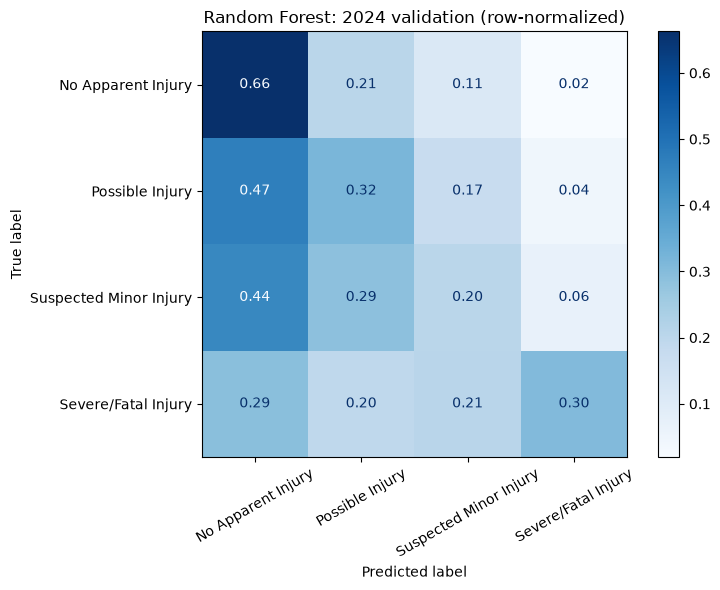

In [173]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Combine with the four-class results from Experiment B.
all_four_class_comparison = (
    pd.concat(
        [four_class_comparison, pd.DataFrame(tree_results)],
        ignore_index=True
    )
    .sort_values("Macro F1", ascending=False)
    .reset_index(drop=True)
)

print("Four-class validation comparison (2022-2023 train, 2024 validation):")
display(all_four_class_comparison.round(4))

# Confusion matrix for the best tree model, shown as recall per true class.
tree_predictions = {
    "Random Forest": pred_rf_4,
    "Histogram Gradient Boosting": pred_hgb_4,
    "XGBoost": pred_xgb_4
}

best_tree_name = (
    pd.DataFrame(tree_results)
    .sort_values("Macro F1", ascending=False)
    .iloc[0]["Model"]
)

fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(
    y_val_4,
    tree_predictions[best_tree_name],
    labels=severity_4,
    normalize="true",
    values_format=".2f",
    xticks_rotation=30,
    cmap="Blues",
    ax=ax
)
ax.set_title(f"{best_tree_name}: 2024 validation (row-normalized)")
plt.tight_layout()
plt.show()

# **Class Balancing Revisited: Logistic Regression vs Random Forest**
This finishes the class-balancing comparison started above, with two fixes:
- **Category labels are now consistent across years** (see *Harmonize category labels that changed in 2024* in the cleaning section). Before this fix, 4 of the 13 features looked like unknown categories on 2024 data, which is what made SMOTENC predict only "No Apparent Injury".
- **Random undersampling now fully balances the classes.** The earlier version only cut "No Apparent Injury" to 10,000 rows, leaving it about 3x larger than the next class, with no class weights.

Setup: four-class target, train on 2022-2023, validate on 2024. Each method is run on both logistic regression and random forest, using the same classifier settings as earlier, so only the balancing changes.
- SMOTE is logistic regression only: it interpolates between rows, which does not make sense for random forest's integer category codes. SMOTENC is the version built for mixed numeric/categorical data and is run on both.
- Balanced Random Forest (imbalanced-learn) is random forest only: each tree gets its own balanced undersample.

Define the balancing pipelines

In [174]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler, SMOTE, SMOTENC
from imblearn.under_sampling import RandomUnderSampler
from imblearn.ensemble import BalancedRandomForestClassifier

# Every method uses the same classifier settings, so only the balancing changes.
def make_classifier(model, class_weighted):
    if model == "Logistic Regression":
        return LogisticRegression(
            class_weight="balanced" if class_weighted else None,
            max_iter=2000,
            random_state=42
        )

    return RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=20,
        class_weight="balanced_subsample" if class_weighted else None,
        n_jobs=-1,
        random_state=42
    )


# Logistic regression uses scaling + one-hot (preprocessor, cell 80).
# Random forest uses ordinal codes (tree_preprocessor, tree section).
def make_encoder(model):
    if model == "Logistic Regression":
        return clone(preprocessor)
    return clone(tree_preprocessor)


# SMOTENC needs categories as integer codes while it creates synthetic rows.
# tree_preprocessor already outputs numeric columns first, then integer codes.
smotenc_cat_indices = list(range(
    len(numeric_features),
    len(numeric_features) + len(categorical_features)
))


def make_post_smotenc_encoder(model):
    # After SMOTENC, logistic regression still needs scaling + one-hot.
    if model == "Logistic Regression":
        return ColumnTransformer(transformers=[
            ("num", StandardScaler(), list(range(len(numeric_features)))),
            ("cat", OneHotEncoder(
                handle_unknown="ignore",
                min_frequency=10
            ), smotenc_cat_indices)
        ])
    # Random forest can use the integer codes directly.
    return "passthrough"


def make_balancing_pipeline(method, model):
    if method == "Class weights":
        return Pipeline(steps=[
            ("encoder", make_encoder(model)),
            ("classifier", make_classifier(model, class_weighted=True))
        ])

    if method == "Random oversampling":
        return ImbPipeline(steps=[
            ("encoder", make_encoder(model)),
            ("resampler", RandomOverSampler(random_state=42)),
            ("classifier", make_classifier(model, class_weighted=False))
        ])

    if method == "Random undersampling":
        # Default strategy: shrink every class to the size of the smallest one.
        # (The earlier version only cut the majority to 10,000, which left the
        # data heavily imbalanced.)
        return ImbPipeline(steps=[
            ("encoder", make_encoder(model)),
            ("resampler", RandomUnderSampler(random_state=42)),
            ("classifier", make_classifier(model, class_weighted=False))
        ])

    if method == "SMOTE":
        # SMOTE interpolates between rows, so it runs on the one-hot columns.
        # Logistic regression only: on ordinal codes it would invent
        # in-between category codes that mean nothing.
        return ImbPipeline(steps=[
            ("encoder", make_encoder(model)),
            ("resampler", SMOTE(random_state=42)),
            ("classifier", make_classifier(model, class_weighted=False))
        ])

    if method == "SMOTENC":
        return ImbPipeline(steps=[
            ("encoder", clone(tree_preprocessor)),
            ("resampler", SMOTENC(
                categorical_features=smotenc_cat_indices,
                random_state=42
            )),
            ("post_encoder", make_post_smotenc_encoder(model)),
            ("classifier", make_classifier(model, class_weighted=False))
        ])

    if method == "Balanced Random Forest":
        # Random forest only: each tree is trained on its own
        # undersampled, balanced sample, so less data is thrown away overall.
        return Pipeline(steps=[
            ("encoder", clone(tree_preprocessor)),
            ("classifier", BalancedRandomForestClassifier(
                n_estimators=300,
                sampling_strategy="all",
                replacement=True,
                bootstrap=False,
                n_jobs=-1,
                random_state=42
            ))
        ])

    raise ValueError(f"Unknown method: {method}")


balancing_plan = {
    "Logistic Regression": [
        "Class weights",
        "Random oversampling",
        "Random undersampling",
        "SMOTE",
        "SMOTENC"
    ],
    "Random Forest": [
        "Class weights",
        "Random oversampling",
        "Random undersampling",
        "SMOTENC",
        "Balanced Random Forest"
    ]
}

print("Balancing pipelines defined.")

Balancing pipelines defined.


Fit every model/method combination and compare on 2024 validation

In [175]:
import time
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    recall_score
)

# Train on 2022-2023, validate on 2024, four-class target (same as above).
balancing_rows = []
balancing_predictions = {}

for model, methods in balancing_plan.items():
    for method in methods:
        start = time.time()

        pipeline = make_balancing_pipeline(method, model)
        pipeline.fit(X_train, y_train_4)
        predictions = pipeline.predict(X_val)

        balancing_predictions[(model, method)] = predictions

        # Recall per class shows which severity levels each method can find.
        class_recall = recall_score(
            y_val_4,
            predictions,
            labels=severity_4,
            average=None,
            zero_division=0
        )

        row = {
            "Model": model,
            "Balancing Method": method,
            "Accuracy": accuracy_score(y_val_4, predictions),
            "Balanced Accuracy": balanced_accuracy_score(y_val_4, predictions),
            "Macro F1": f1_score(
                y_val_4,
                predictions,
                labels=severity_4,
                average="macro",
                zero_division=0
            )
        }

        for label, recall in zip(severity_4, class_recall):
            row[f"Recall: {label}"] = recall

        balancing_rows.append(row)

        print(f"{model:<20} | {method:<23} | "
              f"Macro F1 {row['Macro F1']:.4f} | "
              f"{time.time() - start:.0f}s")

balancing_results = (
    pd.DataFrame(balancing_rows)
    .sort_values("Macro F1", ascending=False)
    .reset_index(drop=True)
)

print("\nClass balancing comparison (2022-2023 train, 2024 validation):")
display(balancing_results.round(3))

d:\schoolcoding\CodingStuff\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


Logistic Regression  | Class weights           | Macro F1 0.2549 | 1s


d:\schoolcoding\CodingStuff\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


Logistic Regression  | Random oversampling     | Macro F1 0.2541 | 3s


d:\schoolcoding\CodingStuff\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


...

d:\schoolcoding\CodingStuff\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


Logistic Regression  | SMOTE                   | Macro F1 0.2613 | 5s


d:\schoolcoding\CodingStuff\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


Logistic Regression  | SMOTENC                 | Macro F1 0.2764 | 8s
Random Forest        | Class weights           | Macro F1 0.3100 | 2s
Random Forest        | Random oversampling     | Macro F1 0.3090 | 3s
Random Forest        | Random undersampling    | Macro F1 0.2470 | 1s
Random Forest        | SMOTENC                 | Macro F1 0.3023 | 12s
Random Forest        | Balanced Random Forest  | Macro F1 0.2747 | 1s

Class balancing comparison (2022-2023 train, 2024 validation):


,Model,Balancing Method,Accuracy,Balanced Accuracy,Macro F1,Recall: No Apparent Injury,Recall: Possible Injury,Recall: Suspected Minor Injury,Recall: Severe/Fatal Injury
0,Random Forest,Class weights,0.592,0.372,0.310,0.663,0.317,0.204,0.305
1,Random Forest,Random oversampling,0.586,0.351,0.309,0.652,0.341,0.222,0.190
2,Random Forest,SMOTENC,0.668,0.337,0.302,0.773,0.184,0.144,0.247
3,Logistic Regression,SMOTENC,0.556,0.368,0.276,0.624,0.212,0.223,0.414
4,Random Forest,Balanced Random Forest,0.493,0.385,0.275,0.532,0.358,0.260,0.391
5,Logistic Regression,SMOTE,0.466,0.402,0.261,0.502,0.300,0.265,0.540
6,Logistic Regression,Class weights,0.439,0.406,0.255,0.465,0.346,0.267,0.546
7,Logistic Regression,Random oversampling,0.437,0.405,0.254,0.463,0.334,0.275,0.546
8,Logistic Regression,Random undersampling,0.451,0.382,0.251,0.485,0.237,0.302,0.506
9,Random Forest,Random undersampling,0.478,0.367,0.247,0.533,0.234,0.168,0.534


Macro F1 by balancing method

Model,Logistic Regression,Random Forest
Balancing Method,,
Class weights,0.255,0.310
Random oversampling,0.254,0.309
Random undersampling,0.251,0.247
SMOTE,0.261,NaN
SMOTENC,0.276,0.302
Balanced Random Forest,NaN,0.275


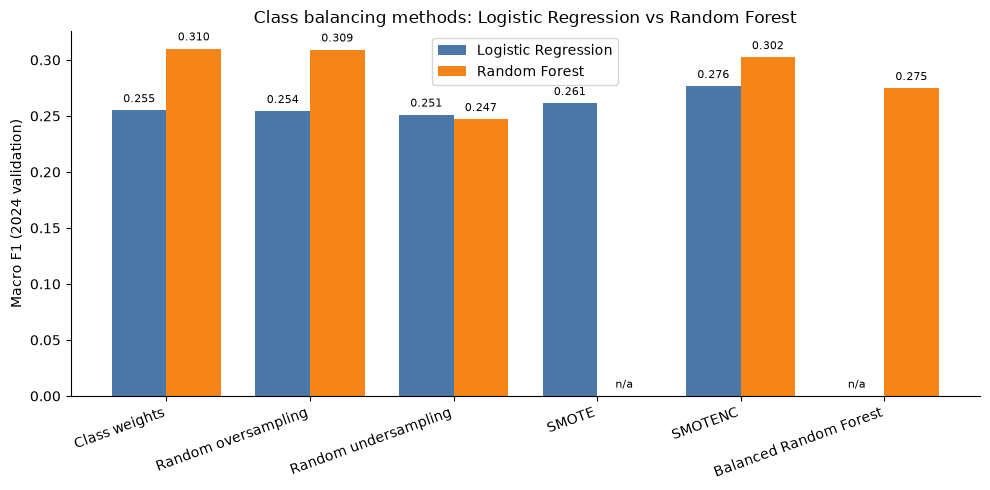

In [176]:
import matplotlib.pyplot as plt
import numpy as np

method_order = [
    "Class weights",
    "Random oversampling",
    "Random undersampling",
    "SMOTE",
    "SMOTENC",
    "Balanced Random Forest"
]

macro_f1_table = balancing_results.pivot(
    index="Balancing Method",
    columns="Model",
    values="Macro F1"
).reindex(method_order)

display(macro_f1_table.round(3))

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(method_order))
bar_width = 0.38

for offset, (model, color) in zip(
    [-bar_width / 2, bar_width / 2],
    [("Logistic Regression", "#4C78A8"), ("Random Forest", "#F58518")]
):
    values = macro_f1_table[model]
    bars = ax.bar(x + offset, values.fillna(0), bar_width,
                  label=model, color=color)

    # Label each bar; methods that do not apply to a model are marked n/a.
    for bar, value in zip(bars, values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            (0 if np.isnan(value) else value) + 0.005,
            "n/a" if np.isnan(value) else f"{value:.3f}",
            ha="center", va="bottom", fontsize=8
        )

ax.set_xticks(x)
ax.set_xticklabels(method_order, rotation=20, ha="right")
ax.set_ylabel("Macro F1 (2024 validation)")
ax.set_title("Class balancing methods: Logistic Regression vs Random Forest")
ax.legend()
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

# **Notes: Class Balancing Revisited**
Validation (2024), four-class target, sorted within each model by Macro F1:

| Model | Method | Accuracy | Balanced Acc. | Macro F1 | Severe/Fatal recall |
|---|---|---|---|---|---|
| Random Forest | Class weights | 0.592 | 0.372 | **0.310** | 0.31 |
| Random Forest | Random oversampling | 0.586 | 0.351 | 0.309 | 0.19 |
| Random Forest | SMOTENC | 0.668 | 0.337 | 0.302 | 0.25 |
| Random Forest | Balanced Random Forest | 0.493 | 0.385 | 0.275 | 0.39 |
| Random Forest | Random undersampling | 0.478 | 0.367 | 0.247 | 0.53 |
| Logistic Regression | SMOTENC | 0.556 | 0.368 | 0.276 | 0.41 |
| Logistic Regression | SMOTE | 0.466 | 0.402 | 0.261 | 0.54 |
| Logistic Regression | Class weights | 0.439 | 0.406 | 0.255 | 0.55 |
| Logistic Regression | Random oversampling | 0.437 | 0.405 | 0.254 | 0.55 |
| Logistic Regression | Random undersampling | 0.451 | 0.382 | 0.251 | 0.51 |

- **Random forest beats logistic regression on Macro F1 for every method except random undersampling.** The model choice matters more than the balancing method.
- **For random forest, simple class weights are best (0.310).** Oversampling is nearly tied (0.309) and SMOTENC is close (0.302), so the extra complexity of synthetic data does not pay off here.
- **For logistic regression, SMOTENC is now the best method (0.276).** In the first run it predicted only "No Apparent Injury"; that was caused by the 2024 label change, not by SMOTENC.
- **Random undersampling is the weakest method for both models.** Fully balancing shrinks every class to 306 rows (the Severe/Fatal count), discarding about 97% of the training data. Balanced Random Forest, which undersamples separately for each tree, recovers part of that (0.275) but still trails class weights.
- **Trade-off:** logistic regression methods have higher balanced accuracy (0.37-0.41) and catch more Severe/Fatal crashes (recall 0.41-0.55, vs 0.31 for the selected random forest). They do this by predicting an injury for roughly half of the uninjured crashes, which drags down precision and Macro F1. If the project's priority is *finding severe crashes* rather than *overall accuracy across classes*, class-weighted logistic regression is a defensible choice. This is a team decision.

# **Final Evaluation on the 2025 Test Set**
- The model with the best 2024 validation Macro F1 (from the balancing comparison, plus Histogram Gradient Boosting and XGBoost) is retrained on all of 2022-2024 and evaluated **once** on 2025.
- Do not tune models after looking at these numbers, or 2025 stops being a fair test.

In [177]:
# Pick the best model on 2024 validation (balancing comparison above,
# plus Histogram Gradient Boosting and XGBoost from the tree section),
# retrain it on all of 2022-2024, and evaluate it ONCE on 2025.

other_tree_results = pd.DataFrame(tree_results)
other_tree_results = other_tree_results[
    other_tree_results["Model"].isin(["Histogram Gradient Boosting", "XGBoost"])
].assign(**{"Balancing Method": "Class weights"})

final_comparison = (
    pd.concat(
        [balancing_results, other_tree_results],
        ignore_index=True
    )
    .sort_values("Macro F1", ascending=False)
    .reset_index(drop=True)
)

display(
    final_comparison[
        ["Model", "Balancing Method", "Accuracy",
         "Balanced Accuracy", "Macro F1"]
    ].round(4)
)

best = final_comparison.iloc[0]
print(f"\nSelected: {best['Model']} with {best['Balancing Method']} "
      f"(validation Macro F1 {best['Macro F1']:.4f})")

merge_severe_fatal = {
    "Suspected Serious Injury": severe_fatal_label,
    "Fatal Injury": severe_fatal_label
}

test_2025 = df_2022_2025[
    (df_2022_2025["Crash Year"] == 2025)
    & (df_2022_2025[target].isin(valid_severity))
].copy()

X_dev = df_development[features]
y_dev_4 = df_development[target].replace(merge_severe_fatal)

X_test_2025 = test_2025[features]
y_test_2025_4 = test_2025[target].replace(merge_severe_fatal)

print("Development rows (2022-2024):", len(X_dev))
print("Test rows (2025):", len(X_test_2025))

if best["Model"] in tree_pipelines:
    final_model = fit_four_class(best["Model"], X_dev, y_dev_4)
    pred_test_2025 = predict_four_class(best["Model"], final_model, X_test_2025)
else:
    final_model = make_balancing_pipeline(
        best["Balancing Method"], best["Model"]
    ).fit(X_dev, y_dev_4)
    pred_test_2025 = final_model.predict(X_test_2025)

final_test_result = evaluate_four_class(
    f"{best['Model']} ({best['Balancing Method']}): 2025 test",
    y_test_2025_4,
    pred_test_2025
)

display(pd.DataFrame([final_test_result]).round(4))

,Model,Balancing Method,Accuracy,Balanced Accuracy,Macro F1
0,Random Forest,Class weights,0.5923,0.3721,0.3100
1,Random Forest,Random oversampling,0.5856,0.3513,0.3090
2,Random Forest,SMOTENC,0.6678,0.3370,0.3023
3,XGBoost,Class weights,0.5024,0.3618,0.2789
4,Logistic Regression,SMOTENC,0.5556,0.3681,0.2764
5,Random Forest,Balanced Random Forest,0.4930,0.3852,0.2747
6,Histogram Gradient Boosting,Class weights,0.4620,0.4062,0.2695
7,Logistic Regression,SMOTE,0.4664,0.4018,0.2613
8,Logistic Regression,Class weights,0.4390,0.4061,0.2549
9,Logistic Regression,Random oversampling,0.4374,0.4046,0.2541



Selected: Random Forest with Class weights (validation Macro F1 0.3100)
Development rows (2022-2024): 53968
Test rows (2025): 16616

Random Forest (Class weights): 2025 test
                        precision    recall  f1-score   support

    No Apparent Injury       0.88      0.65      0.75     13759
       Possible Injury       0.11      0.28      0.16      1243
Suspected Minor Injury       0.14      0.26      0.18      1462
   Severe/Fatal Injury       0.08      0.28      0.12       152

              accuracy                           0.59     16616
             macro avg       0.30      0.37      0.30     16616
          weighted avg       0.75      0.59      0.65     16616



,Model,Accuracy,Balanced Accuracy,Macro F1
0,Random Forest (Class weights): 2025 test,0.5867,0.3677,0.3028


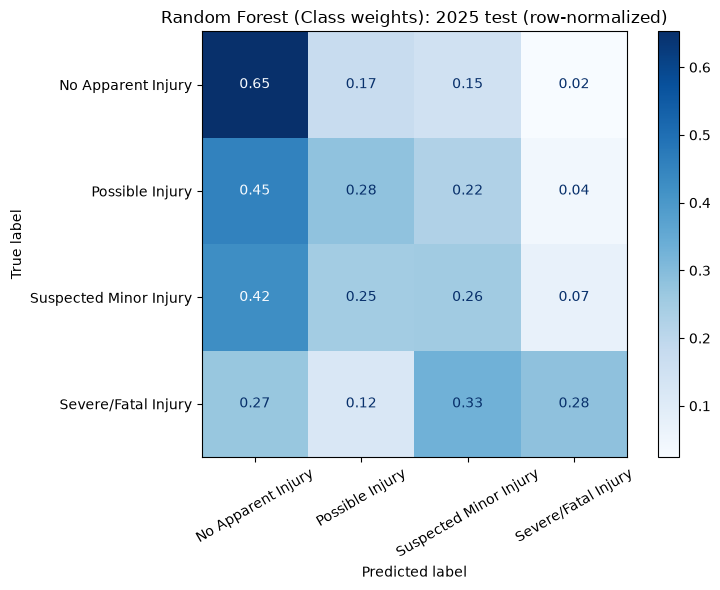

In [178]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test_2025_4,
    pred_test_2025,
    labels=severity_4,
    normalize="true",
    values_format=".2f",
    xticks_rotation=30,
    cmap="Blues",
    ax=ax
)
ax.set_title(
    f"{best['Model']} ({best['Balancing Method']}): 2025 test (row-normalized)"
)
plt.tight_layout()
plt.show()

# **Notes: Final Model on 2025**
Selected model: **Random Forest with class weights** (best 2024 validation Macro F1, 0.310), retrained on 2022-2024.

| 2025 test | Accuracy | Balanced Accuracy | Macro F1 |
|---|---|---|---|
| Random Forest + class weights | 0.587 | 0.368 | **0.303** |
| *For reference: same model before the label fix* | *0.574* | *0.360* | *0.283* |

Recall by class on 2025: No Apparent Injury 0.65, Possible Injury 0.28, Suspected Minor Injury 0.26, Severe/Fatal Injury 0.28.

- Macro F1 on 2025 (0.303) is close to validation (0.310), so the model generalizes to a new year rather than fitting 2024.
- After the label fix, recall is spread much more evenly across the injury classes. Before the fix it was 0.03 for Possible Injury and 0.52 for Suspected Minor Injury.
- **Precision for the injury classes is low (0.08-0.14).** Most crashes the model flags as injuries are actually no-injury crashes. The confusion matrix shows that injury levels are also often confused with each other: only 28% of Severe/Fatal crashes are predicted as Severe/Fatal, and 33% are predicted as Suspected Minor.
- **Overall, crash-level features (collision type, road, weather, light, time, vehicle type) only weakly predict injury severity.** Factors that are likely more predictive, such as occupant age, seat-belt use, or impact speed, are not in this dataset. This is worth stating as a limitation.
- The 2025 test set was evaluated twice: once before and once after the label fix. Model selection used 2024 validation both times.

# **Feature Selection (Random Forest + Class Weights)**
The 13 features used so far were hand-picked. This section tests, using **only 2022-2023 training and 2024 validation**:
1. **Forward step:** does adding any unused column improve the model?
2. **Backward step:** can any features be removed without losing performance?

Rules, fixed before running:
- The forest's own randomness moves Macro F1 a little from run to run. A change only counts if it beats **2x the seed-to-seed standard deviation**.
- Because the backward step compares many feature sets on the same validation data, the final choice is **re-checked with 6 new random seeds**.

**Candidates tested:** Driver Substance Abuse, Driver Distracted By, Vehicle First Impact Location, Vehicle Age (from Vehicle Year), out-of-state license, Parked Vehicle, and crash location (latitude/longitude). Most of these also changed labels in 2024, so they are first mapped into groups that mean the same thing in both periods.

**Not tested:**
- *ACRS Report Type*: it literally says "Injury Crash" or "Property Damage Crash", so it encodes the target.
- IDs, report numbers, dates, and free text (Road Name, Location string).
- Vehicle Make/Model: hundreds of labels, renamed in 2024.
- Agency Name: renamed in 2024, and mostly duplicates location.
- Collision Type: Collision Group is its harmonized version.
- Is Weekend, Crash Time Period, Rush Hour, Crash Season: recodings of hour/day/month, which are already included.
- Driverless Vehicle: 99.8% "No".

**Tested separately, never used:** Vehicle Damage Extent and Driver At Fault. Both are recorded after the crash, and damage extent partly describes the same outcome as injury severity (possible leakage).

Build and harmonize the candidate features

In [179]:
# Candidate features that were not used so far.
# Like the fields fixed in the cleaning section, most of these changed
# their labels in 2024, so each one is mapped onto a small set of groups
# that mean the same thing in both periods.
# normalize_label() comes from the cleaning section.


def substance_group(value):
    """Old: 'ALCOHOL PRESENT', 'NONE DETECTED', ...
    2024+: 'Suspect of Alcohol Use, Not Suspect of Drug Use', ..."""
    if pd.isna(value):
        return np.nan
    v = normalize_label(value)

    if "suspect" in v and "," in str(value):
        # 2024+ format: "<alcohol part>, <drug part>"
        alcohol_part, drug_part = [
            normalize_label(part) for part in str(value).split(",", 1)
        ]
        alcohol = alcohol_part.startswith("suspect")
        drugs = drug_part.startswith("suspect")
        none = (alcohol_part.startswith("not suspect")
                and drug_part.startswith("not suspect"))
    else:
        alcohol = "alcohol" in v or "combin" in v
        drugs = "drug" in v or "medication" in v or "combin" in v
        none = v == "none detected"

    if alcohol and drugs:
        return "Alcohol and Drugs"
    if alcohol:
        return "Alcohol"
    if drugs:
        return "Drugs"
    if none:
        return "None"
    return "Unknown"


def distraction_group(value):
    """Old: 20 detailed labels. 2024+: 6 broad labels."""
    if pd.isna(value):
        return np.nan
    v = normalize_label(value)

    if v == "not distracted":
        return "No"
    # 2024+ has no "looked but did not see" category; it describes a
    # perception error rather than a distraction, so it counts as No.
    if v == "looked but did not see":
        return "No"
    if v in ("unknown", "no driver present"):
        return "Unknown"
    return "Yes"


CLOCK_TO_SIDE = {
    "eleven": "Front", "twelve": "Front", "one": "Front",
    "two": "Right", "three": "Right", "four": "Right",
    "five": "Rear", "six": "Rear", "seven": "Rear",
    "eight": "Left", "nine": "Left", "ten": "Left"
}


def impact_side(value):
    """Old: 'TWELVE OCLOCK'. 2024+: 'Twelve O Clock'."""
    if pd.isna(value):
        return np.nan
    v = normalize_label(value)
    first_word = v.split(" ")[0]

    if first_word in CLOCK_TO_SIDE:
        return CLOCK_TO_SIDE[first_word]
    if v in ("unknown", "vehicle not at scene"):
        return "Unknown"
    return "Other"  # roof, underside, non-collision, cargo loss


def damage_group(value):
    """Leakage check only. 2024+ has no 'Destroyed' category."""
    if pd.isna(value):
        return np.nan
    v = normalize_label(value)

    if v in ("destroyed", "disabling"):
        return "Disabling/Destroyed"
    if v in ("functional", "superficial", "no damage"):
        return v.title()
    return "Unknown"


def add_candidate_features(data):
    data = data.copy()

    data["Substance Suspected"] = data["Driver Substance Abuse"].map(substance_group)
    data["Driver Distracted"] = data["Driver Distracted By"].map(distraction_group)
    data["Impact Side"] = data["Vehicle First Impact Location"].map(impact_side)

    # Vehicle Year contains placeholders such as 0 and 9999.
    vehicle_age = data["Crash Year"] - data["Vehicle Year"]
    data["Vehicle Age"] = vehicle_age.where(vehicle_age.between(0, 40))

    data["License State Group"] = data["Drivers License State"].map(
        lambda x: np.nan if pd.isna(x)
        else "Maryland" if x == "MD"
        else "Out of State"
    )

    # Leakage check only (recorded after the crash)
    data["Damage Extent Group"] = data["Vehicle Damage Extent"].map(damage_group)

    return data


df_2022_2025 = add_candidate_features(df_2022_2025)

df_development = df_2022_2025[
    df_2022_2025["Crash Year"].isin([2022, 2023, 2024])
    & df_2022_2025[target].isin(valid_severity)
].copy()

new_columns = [
    "Substance Suspected",
    "Driver Distracted",
    "Impact Side",
    "License State Group",
    "Parked Vehicle",
    "Damage Extent Group",
    "Driver At Fault"
]

# Check: each group should have a similar share in both periods.
period = np.where(df_2022_2025["Crash Year"] <= 2023, "2022-2023", "2024-2025")

for col in new_columns:
    shares = (
        pd.crosstab(df_2022_2025[col].fillna("<missing>"), period, normalize="columns")
        .mul(100)
        .round(1)
    )
    print(f"\n{col} (% of records):")
    print(shares.to_string())

print("\nVehicle Age summary:")
print(df_2022_2025.groupby(period)["Vehicle Age"].describe().round(1).to_string())


Substance Suspected (% of records):
col_0                2022-2023  2024-2025
Substance Suspected                      
<missing>                 18.1        0.0
Alcohol                    3.0        2.7
Alcohol and Drugs          0.1        0.2
Drugs                      0.2        0.1
None                      70.4       85.6
Unknown                    8.2       11.4

Driver Distracted (% of records):
col_0              2022-2023  2024-2025
Driver Distracted                      
<missing>                0.0        7.3
No                      72.6       66.0
Unknown                 21.5       23.5
Yes                      5.9        3.1

Impact Side (% of records):
col_0        2022-2023  2024-2025
Impact Side                      
Front             57.2       50.5
Left               8.8        9.7
Other              0.7        2.2
Rear              22.1       20.7
Right              9.1        9.7
Unknown            2.2        7.2

License State Group (% of records):
col_0         

Measure run-to-run noise for the current model

In [180]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score

NUMERIC_COLUMNS = {
    "Speed Limit", "Crash Hour", "Crash Day of Week", "Crash Month",
    "Vehicle Age", "Latitude", "Longitude"
}


def make_rf_for(feature_list, random_state=42):
    """The selected model (random forest + class weights) for any feature list."""
    numeric = [f for f in feature_list if f in NUMERIC_COLUMNS]
    categorical = [f for f in feature_list if f not in NUMERIC_COLUMNS]

    encoder = ColumnTransformer(transformers=[
        ("num", SimpleImputer(strategy="median"), numeric),
        ("cat", Pipeline(steps=[
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("ordinal", OrdinalEncoder(
                handle_unknown="use_encoded_value",
                unknown_value=-1,
                min_frequency=10
            ))
        ]), categorical)
    ])

    return Pipeline(steps=[
        ("encoder", encoder),
        ("classifier", RandomForestClassifier(
            n_estimators=300,
            min_samples_leaf=20,
            class_weight="balanced_subsample",
            n_jobs=-1,
            random_state=random_state
        ))
    ])


merge_severe_fatal = {
    "Suspected Serious Injury": severe_fatal_label,
    "Fatal Injury": severe_fatal_label
}

# Same split as before: train 2022-2023, validate 2024.
fs_train = df_development[df_development["Crash Year"].isin([2022, 2023])]
fs_val = df_development[df_development["Crash Year"] == 2024]
y_fs_train = fs_train[target].replace(merge_severe_fatal)
y_fs_val = fs_val[target].replace(merge_severe_fatal)


def validation_macro_f1(feature_list, random_state=42):
    model = make_rf_for(feature_list, random_state)
    model.fit(fs_train[feature_list], y_fs_train)
    return f1_score(
        y_fs_val,
        model.predict(fs_val[feature_list]),
        labels=severity_4,
        average="macro",
        zero_division=0
    )


base_features = list(features)
base_score = validation_macro_f1(base_features)

# How much does the score move just from the forest's randomness?
# A feature change only counts if it beats this noise.
seed_scores = [validation_macro_f1(base_features, seed) for seed in range(5)]
noise_sd = np.std(seed_scores, ddof=1)
min_gain = 2 * noise_sd

print(f"Baseline ({len(base_features)} features), validation Macro F1: {base_score:.4f}")
print("Scores with 5 different random seeds:", np.round(seed_scores, 4))
print(f"Seed-to-seed standard deviation: {noise_sd:.4f}")
print(f"A change must move Macro F1 by more than {min_gain:.4f} to count.")

Baseline (13 features), validation Macro F1: 0.3100
Scores with 5 different random seeds: [0.3084 0.3096 0.3045 0.3087 0.3113]
Seed-to-seed standard deviation: 0.0025
A change must move Macro F1 by more than 0.0050 to count.


Permutation importance of the current 13 features
- Each feature is shuffled on the 2024 validation data, and the drop in Macro F1 is measured. A bigger drop means the model relies on it more.
- **Note:** features that overlap with each other (e.g. hour, month, and location) can each look unimportant even when the group matters, so this ranking alone is not used to drop features.

,Feature,Importance,Std
0,Vehicle Body Type,0.0304,0.0017
1,Collision Group,0.0210,0.0043
2,Speed Limit,0.0140,0.0038
3,Vehicle Going Dir,0.0058,0.0012
4,Crash Month,0.0049,0.0021
5,Crash Hour,0.0048,0.0018
6,Traffic Control,0.0014,0.0026
7,Vehicle Movement,0.0008,0.0030
8,Route Type,0.0007,0.0014
9,Surface Condition,-0.0002,0.0010


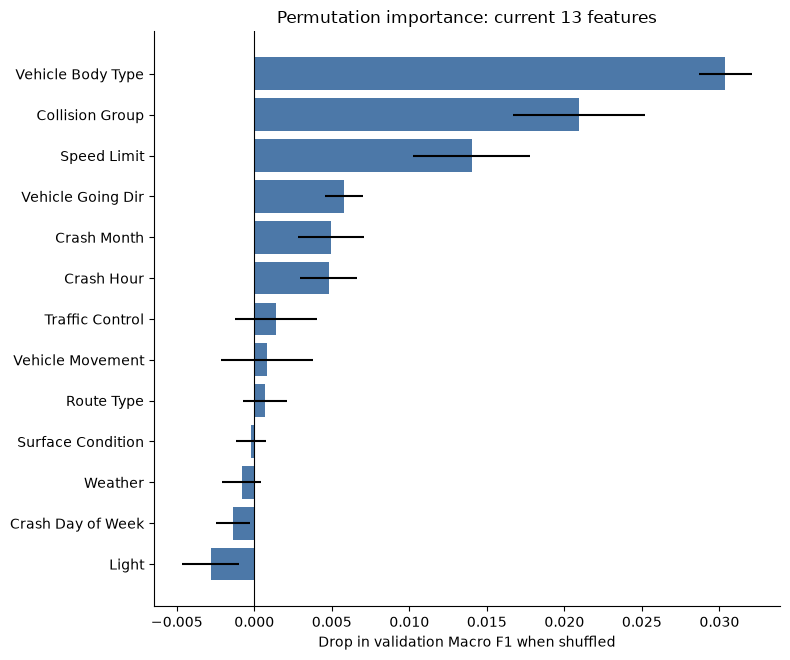

In [181]:
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance


def macro_f1_scorer(estimator, X, y):
    return f1_score(
        y,
        estimator.predict(X),
        labels=severity_4,
        average="macro",
        zero_division=0
    )


def permutation_table(feature_list):
    """Shuffle one feature at a time on 2024 validation and measure the drop
    in Macro F1. A drop near zero means the model barely uses the feature."""
    model = make_rf_for(feature_list).fit(fs_train[feature_list], y_fs_train)

    result = permutation_importance(
        model,
        fs_val[feature_list],
        y_fs_val,
        scoring=macro_f1_scorer,
        n_repeats=5,
        random_state=42
    )

    return pd.DataFrame({
        "Feature": feature_list,
        "Importance": result.importances_mean,
        "Std": result.importances_std
    }).sort_values("Importance", ascending=False).reset_index(drop=True)


def plot_importance(table, title):
    ordered = table.sort_values("Importance")
    fig, ax = plt.subplots(figsize=(8, 0.4 * len(ordered) + 1.5))
    ax.barh(ordered["Feature"], ordered["Importance"],
            xerr=ordered["Std"], color="#4C78A8")
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_xlabel("Drop in validation Macro F1 when shuffled")
    ax.set_title(title)
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    plt.show()


base_importance = permutation_table(base_features)
display(base_importance.round(4))
plot_importance(base_importance, "Permutation importance: current 13 features")

Forward step: add each candidate on its own

In [182]:
# Add each candidate (or pair, for location) to the current 13 features,
# one at a time, and compare against the baseline score.
candidate_groups = {
    "Substance Suspected": ["Substance Suspected"],
    "Driver Distracted": ["Driver Distracted"],
    "Impact Side": ["Impact Side"],
    "Vehicle Age": ["Vehicle Age"],
    "License State Group": ["License State Group"],
    "Parked Vehicle": ["Parked Vehicle"],
    "Location (Latitude/Longitude)": ["Latitude", "Longitude"]
}

forward_rows = []

for name, columns in candidate_groups.items():
    score = validation_macro_f1(base_features + columns)
    forward_rows.append({
        "Candidate": name,
        "Macro F1": score,
        "Change vs baseline": score - base_score,
        "Keep": score - base_score > min_gain
    })

forward_results = (
    pd.DataFrame(forward_rows)
    .sort_values("Change vs baseline", ascending=False)
    .reset_index(drop=True)
)

print(f"Baseline Macro F1: {base_score:.4f}  |  required gain: > {min_gain:.4f}")
display(forward_results.round(4))

kept_groups = forward_results.loc[forward_results["Keep"], "Candidate"].tolist()

expanded_features = base_features + [
    column
    for name in kept_groups
    for column in candidate_groups[name]
]
expanded_score = validation_macro_f1(expanded_features)

print("Candidates kept:", kept_groups)
print(f"All kept candidates together ({len(expanded_features)} features): "
      f"Macro F1 {expanded_score:.4f}")

Baseline Macro F1: 0.3100  |  required gain: > 0.0050


,Candidate,Macro F1,Change vs baseline,Keep
0,Location (Latitude/Longitude),0.3298,0.0197,True
1,Vehicle Age,0.3163,0.0063,True
2,Impact Side,0.3143,0.0043,False
3,Driver Distracted,0.3103,0.0003,False
4,Substance Suspected,0.3086,-0.0014,False
5,License State Group,0.3059,-0.0041,False
6,Parked Vehicle,0.3053,-0.0048,False


Candidates kept: ['Location (Latitude/Longitude)', 'Vehicle Age']
All kept candidates together (16 features): Macro F1 0.3331


Backward step: remove features one at a time

,Feature,Importance,Std
0,Vehicle Body Type,0.0403,0.0012
1,Collision Group,0.0244,0.0033
2,Speed Limit,0.0103,0.0037
3,Latitude,0.0062,0.0020
4,Vehicle Age,0.0038,0.0021
5,Surface Condition,0.0029,0.0011
6,Traffic Control,0.0029,0.0026
7,Crash Hour,0.0028,0.0024
8,Longitude,0.0027,0.0024
9,Crash Month,0.0017,0.0016


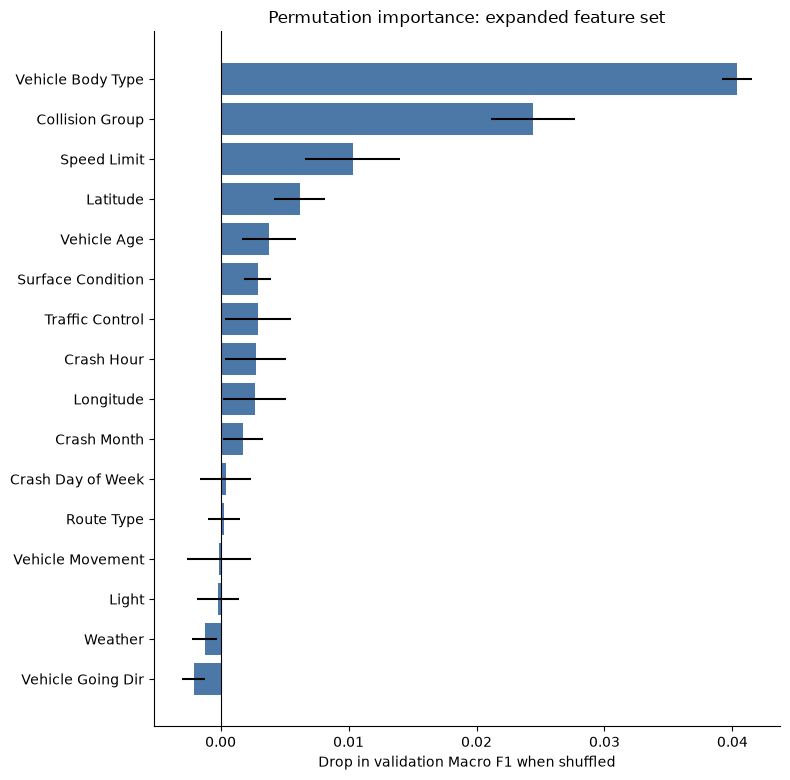

Dropped Speed Limit          -> 15 features, Macro F1 0.3366 (45s)
Dropped Route Type           -> 14 features, Macro F1 0.3364 (37s)
Dropped Surface Condition    -> 13 features, Macro F1 0.3372 (35s)
Dropped Vehicle Going Dir    -> 12 features, Macro F1 0.3355 (33s)
Dropped Light                -> 11 features, Macro F1 0.3351 (36s)
Dropped Weather              -> 10 features, Macro F1 0.3299 (32s)
Stop: the least harmful removal (Collision Group) would drop Macro F1 to 0.3236, below the floor of 0.3281.


,Dropped,Features left,Macro F1 after drop
0,(none - expanded set),16,0.3331
1,Speed Limit,15,0.3366
2,Route Type,14,0.3364
3,Surface Condition,13,0.3372
4,Vehicle Going Dir,12,0.3355
5,Light,11,0.3351
6,Weather,10,0.3299



Best set on the path: 13 features, Macro F1 0.3372
Dropped from the expanded set: ['Surface Condition', 'Speed Limit', 'Route Type']


In [183]:
import time

# Backward step: greedy backward elimination, one feature at a time.
# Each round, try removing every remaining feature and drop the one whose
# removal hurts least (or helps most). Continue until every removal would
# push the score below the expanded set's score minus the noise threshold.
# The selected set is the best-scoring set seen along the way.
# (Features overlap: e.g. hour and month each look weak alone, so dropping
# all weak features at once is not safe.)
expanded_importance = permutation_table(expanded_features)
display(expanded_importance.round(4))
plot_importance(expanded_importance, "Permutation importance: expanded feature set")

current_features = list(expanded_features)
current_score = expanded_score
floor_score = expanded_score - min_gain
elimination_log = [{
    "Dropped": "(none - expanded set)",
    "Features left": len(current_features),
    "Macro F1 after drop": expanded_score,
    "Features": list(current_features)
}]

while len(current_features) > 1:
    start = time.time()
    trial_scores = {
        feature: validation_macro_f1(
            [f for f in current_features if f != feature]
        )
        for feature in current_features
    }
    feature_to_drop = max(trial_scores, key=trial_scores.get)
    score_without = trial_scores[feature_to_drop]

    if score_without < floor_score:
        print(f"Stop: the least harmful removal ({feature_to_drop}) "
              f"would drop Macro F1 to {score_without:.4f}, "
              f"below the floor of {floor_score:.4f}.")
        break

    current_features.remove(feature_to_drop)
    current_score = score_without
    elimination_log.append({
        "Dropped": feature_to_drop,
        "Features left": len(current_features),
        "Macro F1 after drop": score_without,
        "Features": list(current_features)
    })
    print(f"Dropped {feature_to_drop:<20} -> {len(current_features)} features, "
          f"Macro F1 {score_without:.4f} ({time.time() - start:.0f}s)")

elimination_path = pd.DataFrame(elimination_log)
display(elimination_path.drop(columns="Features").round(4))

best_step = elimination_path["Macro F1 after drop"].idxmax()
backward_features = elimination_path.loc[best_step, "Features"]
backward_score = elimination_path.loc[best_step, "Macro F1 after drop"]

print(f"\nBest set on the path: {len(backward_features)} features, "
      f"Macro F1 {backward_score:.4f}")
print("Dropped from the expanded set:",
      [f for f in expanded_features if f not in backward_features])

Confirm the choice with new random seeds

In [184]:
# The backward step compares many feature sets on the same validation data,
# so the winner's score is a little optimistic. Re-score the main candidates
# with 6 new random seeds (not used during selection) and keep the set with
# the best average.
confirm_sets = {
    f"Original ({len(base_features)} features)": base_features,
    f"After forward step ({len(expanded_features)} features)": expanded_features,
    f"After backward step ({len(backward_features)} features)": backward_features
}

confirm_rows = []
for name, feature_list in confirm_sets.items():
    scores = [validation_macro_f1(feature_list, seed) for seed in range(100, 106)]
    confirm_rows.append({
        "Feature set": name,
        "Mean Macro F1": np.mean(scores),
        "Std": np.std(scores, ddof=1),
        "Features": feature_list
    })

confirm_results = (
    pd.DataFrame(confirm_rows)
    .sort_values("Mean Macro F1", ascending=False)
    .reset_index(drop=True)
)
display(confirm_results.drop(columns="Features").round(4))

selected_features = confirm_results.loc[0, "Features"]
print(f"Selected: {confirm_results.loc[0, 'Feature set']}")
print("Features:", selected_features)

,Feature set,Mean Macro F1,Std
0,After backward step (13 features),0.3350,0.0020
1,After forward step (16 features),0.3300,0.0023
2,Original (13 features),0.3074,0.0021


Selected: After backward step (13 features)
Features: ['Collision Group', 'Weather', 'Light', 'Traffic Control', 'Vehicle Body Type', 'Vehicle Movement', 'Vehicle Going Dir', 'Crash Hour', 'Crash Day of Week', 'Crash Month', 'Latitude', 'Longitude', 'Vehicle Age']


Leakage check (not used in the final model)

In [185]:
# Leakage check (NOT used in the final model).
# Damage extent and driver fault are recorded after the crash, and damage
# extent partly describes the same outcome as injury severity. A big jump
# here shows how much a model could look "better" by using them.
leakage_rows = []

for name, columns in {
    "Selected features": [],
    "+ Damage Extent Group": ["Damage Extent Group"],
    "+ Driver At Fault": ["Driver At Fault"],
    "+ both": ["Damage Extent Group", "Driver At Fault"]
}.items():
    leakage_rows.append({
        "Feature set": name,
        "Validation Macro F1": validation_macro_f1(selected_features + columns)
    })

leakage_results = pd.DataFrame(leakage_rows)
display(leakage_results.round(4))

,Feature set,Validation Macro F1
0,Selected features,0.3372
1,+ Damage Extent Group,0.3310
2,+ Driver At Fault,0.3270
3,+ both,0.3338


Final evaluation of the selected feature set on 2025
- Same model as before (random forest + class weights), retrained on 2022-2024 with the selected features.
- The feature set was chosen on 2024 validation only.


Random Forest, 13 selected features: 2025 test
                        precision    recall  f1-score   support

    No Apparent Injury       0.87      0.70      0.78     13759
       Possible Injury       0.11      0.25      0.16      1243
Suspected Minor Injury       0.12      0.21      0.15      1462
   Severe/Fatal Injury       0.12      0.25      0.16       152

              accuracy                           0.62     16616
             macro avg       0.31      0.35      0.31     16616
          weighted avg       0.74      0.62      0.67     16616



,Model,Accuracy,Balanced Accuracy,Macro F1
0,"Random Forest, original 13 features",0.5867,0.3677,0.3028
1,"Random Forest, 13 selected features: 2025 test",0.6212,0.3529,0.3126


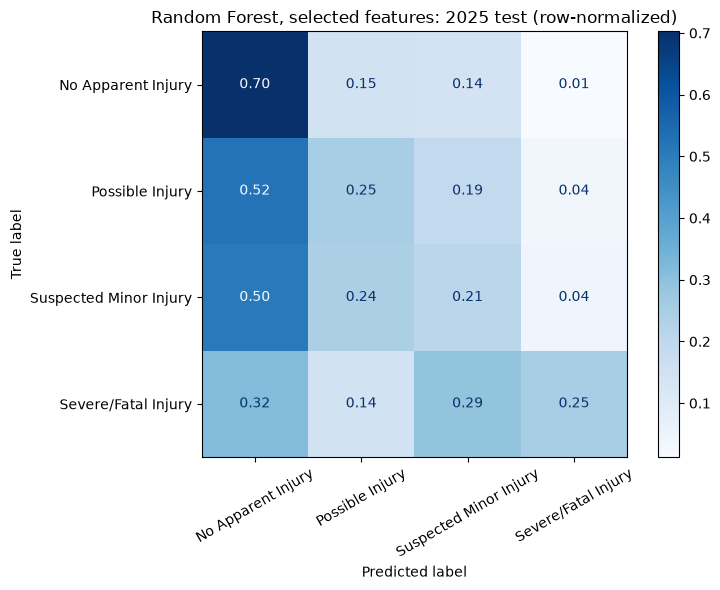

In [186]:
# Retrain random forest + class weights with the selected features on
# all of 2022-2024, then evaluate once on 2025.
# This is the third evaluation on 2025 (see the notes below).
fs_dev = df_development
y_fs_dev = fs_dev[target].replace(merge_severe_fatal)

fs_test = df_2022_2025[
    (df_2022_2025["Crash Year"] == 2025)
    & (df_2022_2025[target].isin(valid_severity))
]
y_fs_test = fs_test[target].replace(merge_severe_fatal)

final_fs_model = make_rf_for(selected_features).fit(
    fs_dev[selected_features], y_fs_dev
)
pred_fs_test = final_fs_model.predict(fs_test[selected_features])

fs_test_result = evaluate_four_class(
    f"Random Forest, {len(selected_features)} selected features: 2025 test",
    y_fs_test,
    pred_fs_test
)

comparison_2025 = pd.DataFrame([
    {**final_test_result, "Model": f"Random Forest, original {len(base_features)} features"},
    fs_test_result
])
display(comparison_2025.round(4))

fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(
    y_fs_test,
    pred_fs_test,
    labels=severity_4,
    normalize="true",
    values_format=".2f",
    xticks_rotation=30,
    cmap="Blues",
    ax=ax
)
ax.set_title("Random Forest, selected features: 2025 test (row-normalized)")
plt.tight_layout()
plt.show()

# **Notes: Feature Selection**
Noise level: the same model with 5 different random seeds varies by SD 0.0025 in validation Macro F1, so a change had to beat **0.005** to count.

**What the current model relies on** (permutation importance, 13 original features): **Vehicle Body Type** matters most, then **Collision Group** and **Speed Limit**. Light, Day of Week, Weather, and Surface Condition contribute almost nothing on their own.

**Forward step** (validation 2024, baseline 0.310):
| Candidate added | Macro F1 | Change | Kept |
|---|---|---|---|
| Location (latitude/longitude) | 0.330 | +0.020 | ✅ |
| Vehicle Age | 0.316 | +0.006 | ✅ |
| Impact Side | 0.314 | +0.004 | ❌ (within noise) |
| Driver Distracted | 0.310 | +0.000 | ❌ |
| Substance Suspected | 0.309 | -0.001 | ❌ |
| License State Group | 0.306 | -0.004 | ❌ |
| Parked Vehicle | 0.305 | -0.005 | ❌ |

**Backward step:** starting from 16 features (0.333), removing Speed Limit, Route Type, and Surface Condition *raised* the score to 0.337. Removing more features lowered it, so the best set has **13 features**.

**Confirmation with 6 new seeds** (mean validation Macro F1): original 13 = **0.307**, forward 16 = **0.330**, selected 13 = **0.335**.

**Selected features:** Collision Group, Weather, Light, Traffic Control, Vehicle Body Type, Vehicle Movement, Vehicle Going Dir, Crash Hour, Crash Day of Week, Crash Month, **Latitude, Longitude, Vehicle Age**.

**2025 test:**
| Model | Accuracy | Balanced Accuracy | Macro F1 |
|---|---|---|---|
| Random Forest, original 13 features | 0.587 | 0.368 | 0.303 |
| **Random Forest, selected 13 features** | **0.621** | 0.353 | **0.313** |

**How to read this:**
- **Location is the biggest gain.** Crash location probably stands in for road type and setting (e.g. rural high-speed roads versus dense downtown streets). It may also partly reflect reporting differences between police agencies.
- **Speed Limit was dropped because it is redundant, not because speed is irrelevant.** Once location is included, the model can infer most of what speed limit tells it. Do not present this as "speed limit doesn't matter".
- **Driver factors did not help.** Distraction and substance use did not improve the model. Both fields are often "Unknown" and changed recording practices in 2024 (the distraction rate roughly halves, and substance data is missing for 18% of 2022-2023 records), so this may reflect data quality more than real effects.
- **The leakage check came back clean.** Adding Damage Extent or Driver At Fault did *not* improve validation Macro F1 (0.327-0.334 vs 0.337), so leaving them out costs nothing.
- **The 2025 gain (+0.010) is smaller than the validation gain (+0.028).** Part of the validation gain comes from choosing the best of many feature sets on the same data, which is expected. The improvement is real but modest.

**Disclosure about the 2025 test set:** while the backward-step rule was being finalized, two other feature sets were also scored on 2025: all 16 features (Macro F1 0.325) and a 10-feature set (0.315). The final set was chosen on 2024 validation only, and is kept even though the 16-feature set happened to score slightly higher on 2025. Switching after seeing test results would make 2025 no longer a fair test. In total, 2025 has been used for: the original model (before and after the label fix), the two development sets above, and this final set.